# Seasonal recharge-oscillator fit: ENSO–IOD free runs and hindcasts

Example workflow for the `explicit_enso_iod_model` package. It replicates the analysis of
`seasonal_freerun_obs_recharge_v2.ipynb` in about 20 short cells:

1. load monthly **E** (Nino3.4), **I** (DMI) and **h** (thermocline) anomalies
2. fit constant baseline coefficients and split E and I into independent/dependent parts with a Kalman filter
3. fit seasonal (annual + semi-annual) coefficients by least squares
4. free-run ensembles: spectra, peak months, seasonal amplitude
5. in-sample hindcast skill vs. lead time, and by initial calendar month

`DATA_SOURCE = "auto"` uses the ORAS5 file or the monthly index CSV if either is present (see `data/README.md`) and otherwise falls back to **synthetic data**, so the notebook runs anywhere.

> **Note:** the figures saved in this notebook were produced from ORAS5 (the first printed line says which source was used). A re-run without that data uses CSV or synthetic data. For latter case numbers and plots will differ and not be indicative of results.

## 1. Setup and data

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import explicit_enso_iod_model as es
except ImportError:            # not pip-installed: use the package next to this notebook folder
    import sys; sys.path.insert(0, "..")
    import explicit_enso_iod_model as es
from explicit_enso_iod_model import diagnostics as dg, plotting as pl

In [2]:
# Where the data live. "auto" uses the first source that exists (oras, then csv) and otherwise
# falls back to synthetic data, so the notebook always runs. Force one with the other values.
DATA_SOURCE = "auto"                           # "auto" | "synthetic" | "csv" | "oras"
CSV_PATH    = "../data/indices_oras5_1958_2023.csv"   # columns: time,E,I,h  (see explicit_enso_iod_model.data)
ORAS_PATH   = "../DATA/ORAS_LowRes.nc"         # your own copy of ORAS5 (not distributed here)

import os
sst_d = None                                    # only set for DATA_SOURCE == "oras" (used for the maps)

if DATA_SOURCE == "auto":
    DATA_SOURCE = ("oras" if os.path.exists(ORAS_PATH) else      # oras first: it also enables the maps
                   "csv" if os.path.exists(CSV_PATH) else "synthetic")

if DATA_SOURCE == "synthetic":
    d = es.synthetic.make_synthetic_obs(n_years=66, seed=0)
    time, E_obs, I_obs, h_obs = d["time"], d["E"], d["I"], d["h"]

elif DATA_SOURCE == "csv":
    if not os.path.exists(CSV_PATH):
        raise FileNotFoundError(f"{CSV_PATH} not found. Put the monthly E, I, h series there "
                                "(columns time,E,I,h) or set DATA_SOURCE = 'synthetic'. "
                                "See data/README.md.")
    d = es.load_indices_csv(CSV_PATH)
    time, E_obs, I_obs, h_obs = d["time"], d["E"], d["I"], d["h"]

elif DATA_SOURCE == "oras":
    if not os.path.exists(ORAS_PATH):
        raise FileNotFoundError(f"{ORAS_PATH} not found. Download ORAS5 yourself (see data/README.md) "
                                "and set ORAS_PATH, or use DATA_SOURCE = 'csv' / 'synthetic'.")
    import xarray as xr
    from explicit_enso_iod_model import indexes as idx
    from explicit_enso_iod_model import climate_base as cb

    dso = xr.open_dataset(ORAS_PATH)
    dso = dso.assign_coords(time=("time_counter", dso.time_counter.data))
    dso = dso.swap_dims({"time_counter": "time"}).drop_vars("time_counter")

    dso_ano, _ = cb.anom(dso)
    sst = dso_ano.sosstsst.sel(lat=slice(30, -30))
    sst_d = cb.detrend_dim(sst, "time", deg=2).sel(time=slice("1958-01", "2023-12"))
    th = dso_ano.so20chgt.sel(lat=slice(30, -30))
    th_d = cb.detrend_dim(th, "time", deg=2).sel(time=slice("1958-01", "2023-12"))

    E_xr, I_xr, h_xr = idx.N34(sst_d), idx.DMI_NOAA(sst_d), idx.EqPac(th_d)
    time, E_obs, I_obs, h_obs = E_xr.time.values, E_xr.values, I_xr.values, h_xr.values

else:
    raise ValueError("DATA_SOURCE must be 'auto', 'synthetic', 'csv' or 'oras'")

print(f"[{DATA_SOURCE}] {len(E_obs)} months: {pd.Timestamp(time[0]).date()} -> {pd.Timestamp(time[-1]).date()}")
print(f"std  E={E_obs.std():.3f}  I={I_obs.std():.3f}  h={h_obs.std():.3f}")

[oras] 792 months: 1958-01-16 -> 2023-12-16
std  E=0.815  I=0.439  h=6.419


## 2. Fit the model

`ExplicitENSOIODModel.fit()` runs the whole chain: baseline AR(1)-type coefficients → Kalman latent states → seasonal regression → process-noise calibration. The hand-tuned Kalman choices (nonlinear coupling `beta_E`, coupling scalings, …) live in `KalmanConfig`; the defaults equal the original notebook values.

In [3]:
model = es.ExplicitENSOIODModel(E_obs, I_obs, h_obs, time=time, dt=1.0)
model.fit(es.KalmanConfig())          # e.g. es.KalmanConfig(beta_E=0.045, coupling_E_to_I_scale=2)

base = {k: v for k, v in model.baseline.items() if k != "h_norm"}
pd.Series(base, name="baseline").round(4).to_frame().T

,alpha_E,coupling_I_to_E,coupling_E_to_I,alpha_I,F1,F2,eps_h,rho_h,h_std,osc_strength,eigen_timescale
baseline,0.0421,0.1116,0.0193,0.2144,0.1104,0.1815,0.0369,0.9638,6.4191,0.02,7.0644


,E obs,I obs,E_I+E_D,I_I+I_D,E_I,E_D,I_I,I_D
std,0.8151,0.439,0.813,0.4375,1.0274,0.6364,0.4526,0.1746


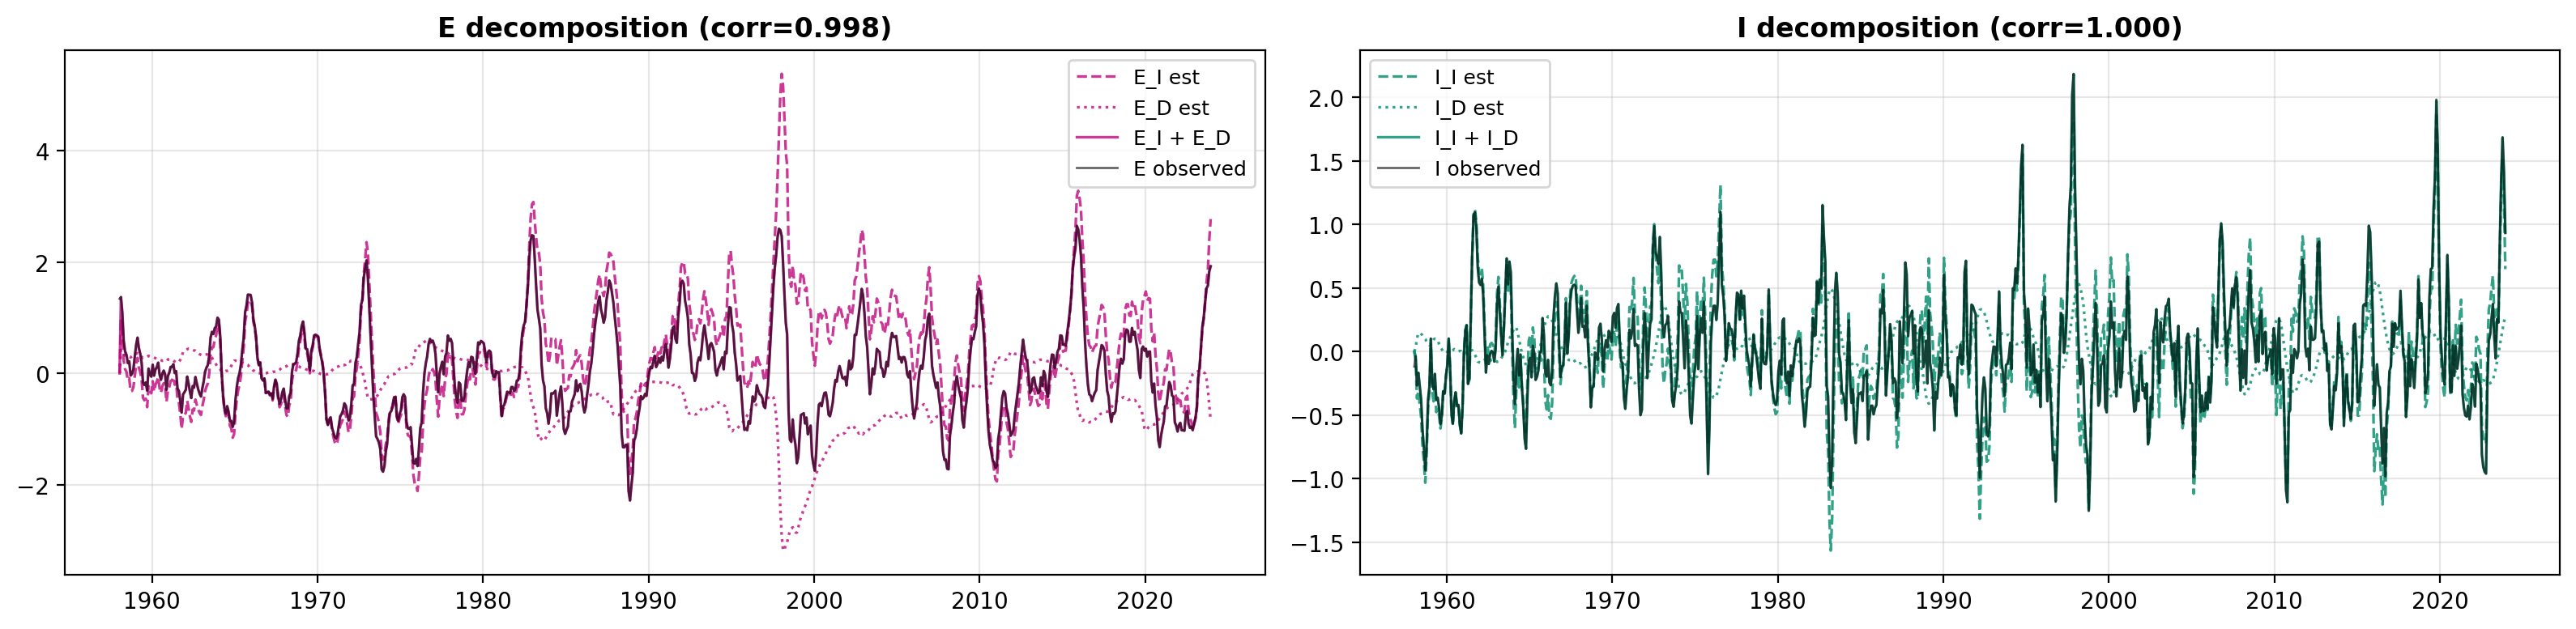

In [4]:
fig, axes = pl.plot_kalman_decomposition(model.time, E_obs, I_obs, model.x_kalman)

est = {"E_I": model.x_kalman[:, 0], "E_D": model.x_kalman[:, 1],
       "I_I": model.x_kalman[:, 2], "I_D": model.x_kalman[:, 3]}
pd.DataFrame({"std": {"E obs": E_obs.std(), "I obs": I_obs.std(),
                      "E_I+E_D": dg.state_total(model.x_kalman, "E").std(),
                      "I_I+I_D": dg.state_total(model.x_kalman, "I").std(),
                      **{k: v.std() for k, v in est.items()}}}).round(4).T

The Kalman part alone (`model.decompose()`, no seasonal fit) gives the four-term split of E and I as a table:

In [5]:
model.decomposition().round(3).iloc[[1, 2, 3, -2, -1]]

,E,I,E_I,E_D,I_I,I_D,h_norm
1958-02-15 00:00:00,1.373,-0.037,0.945,0.423,-0.069,0.033,-1.524
1958-03-16 00:00:00,1.097,-0.268,0.698,0.400,-0.369,0.104,-1.663
1958-04-16 00:00:00,0.585,-0.166,0.237,0.351,-0.311,0.145,-1.846
2023-11-16 00:00:00,1.838,1.413,2.402,-0.570,1.184,0.229,0.278
2023-12-16 12:00:00,1.927,0.933,2.773,-0.851,0.649,0.286,-0.237


## 3. Seasonal parameters

In [6]:
pd.Series(model.fit_summary()).round(4).to_frame("value").T

,alpha_E_L0,a_L0,gamma_E_L0,beta_E_L0,alpha_I_L0,c_L0,gamma_I_L0,sigma_E,sigma_I,rss_alpha_E,rss_alpha_I,rss_E_D,rss_I_D
value,0.0183,0.0,0.0424,0.0895,0.1929,0.0578,0.2143,0.2194,0.2489,38.0161,48.8731,0.185,0.0011


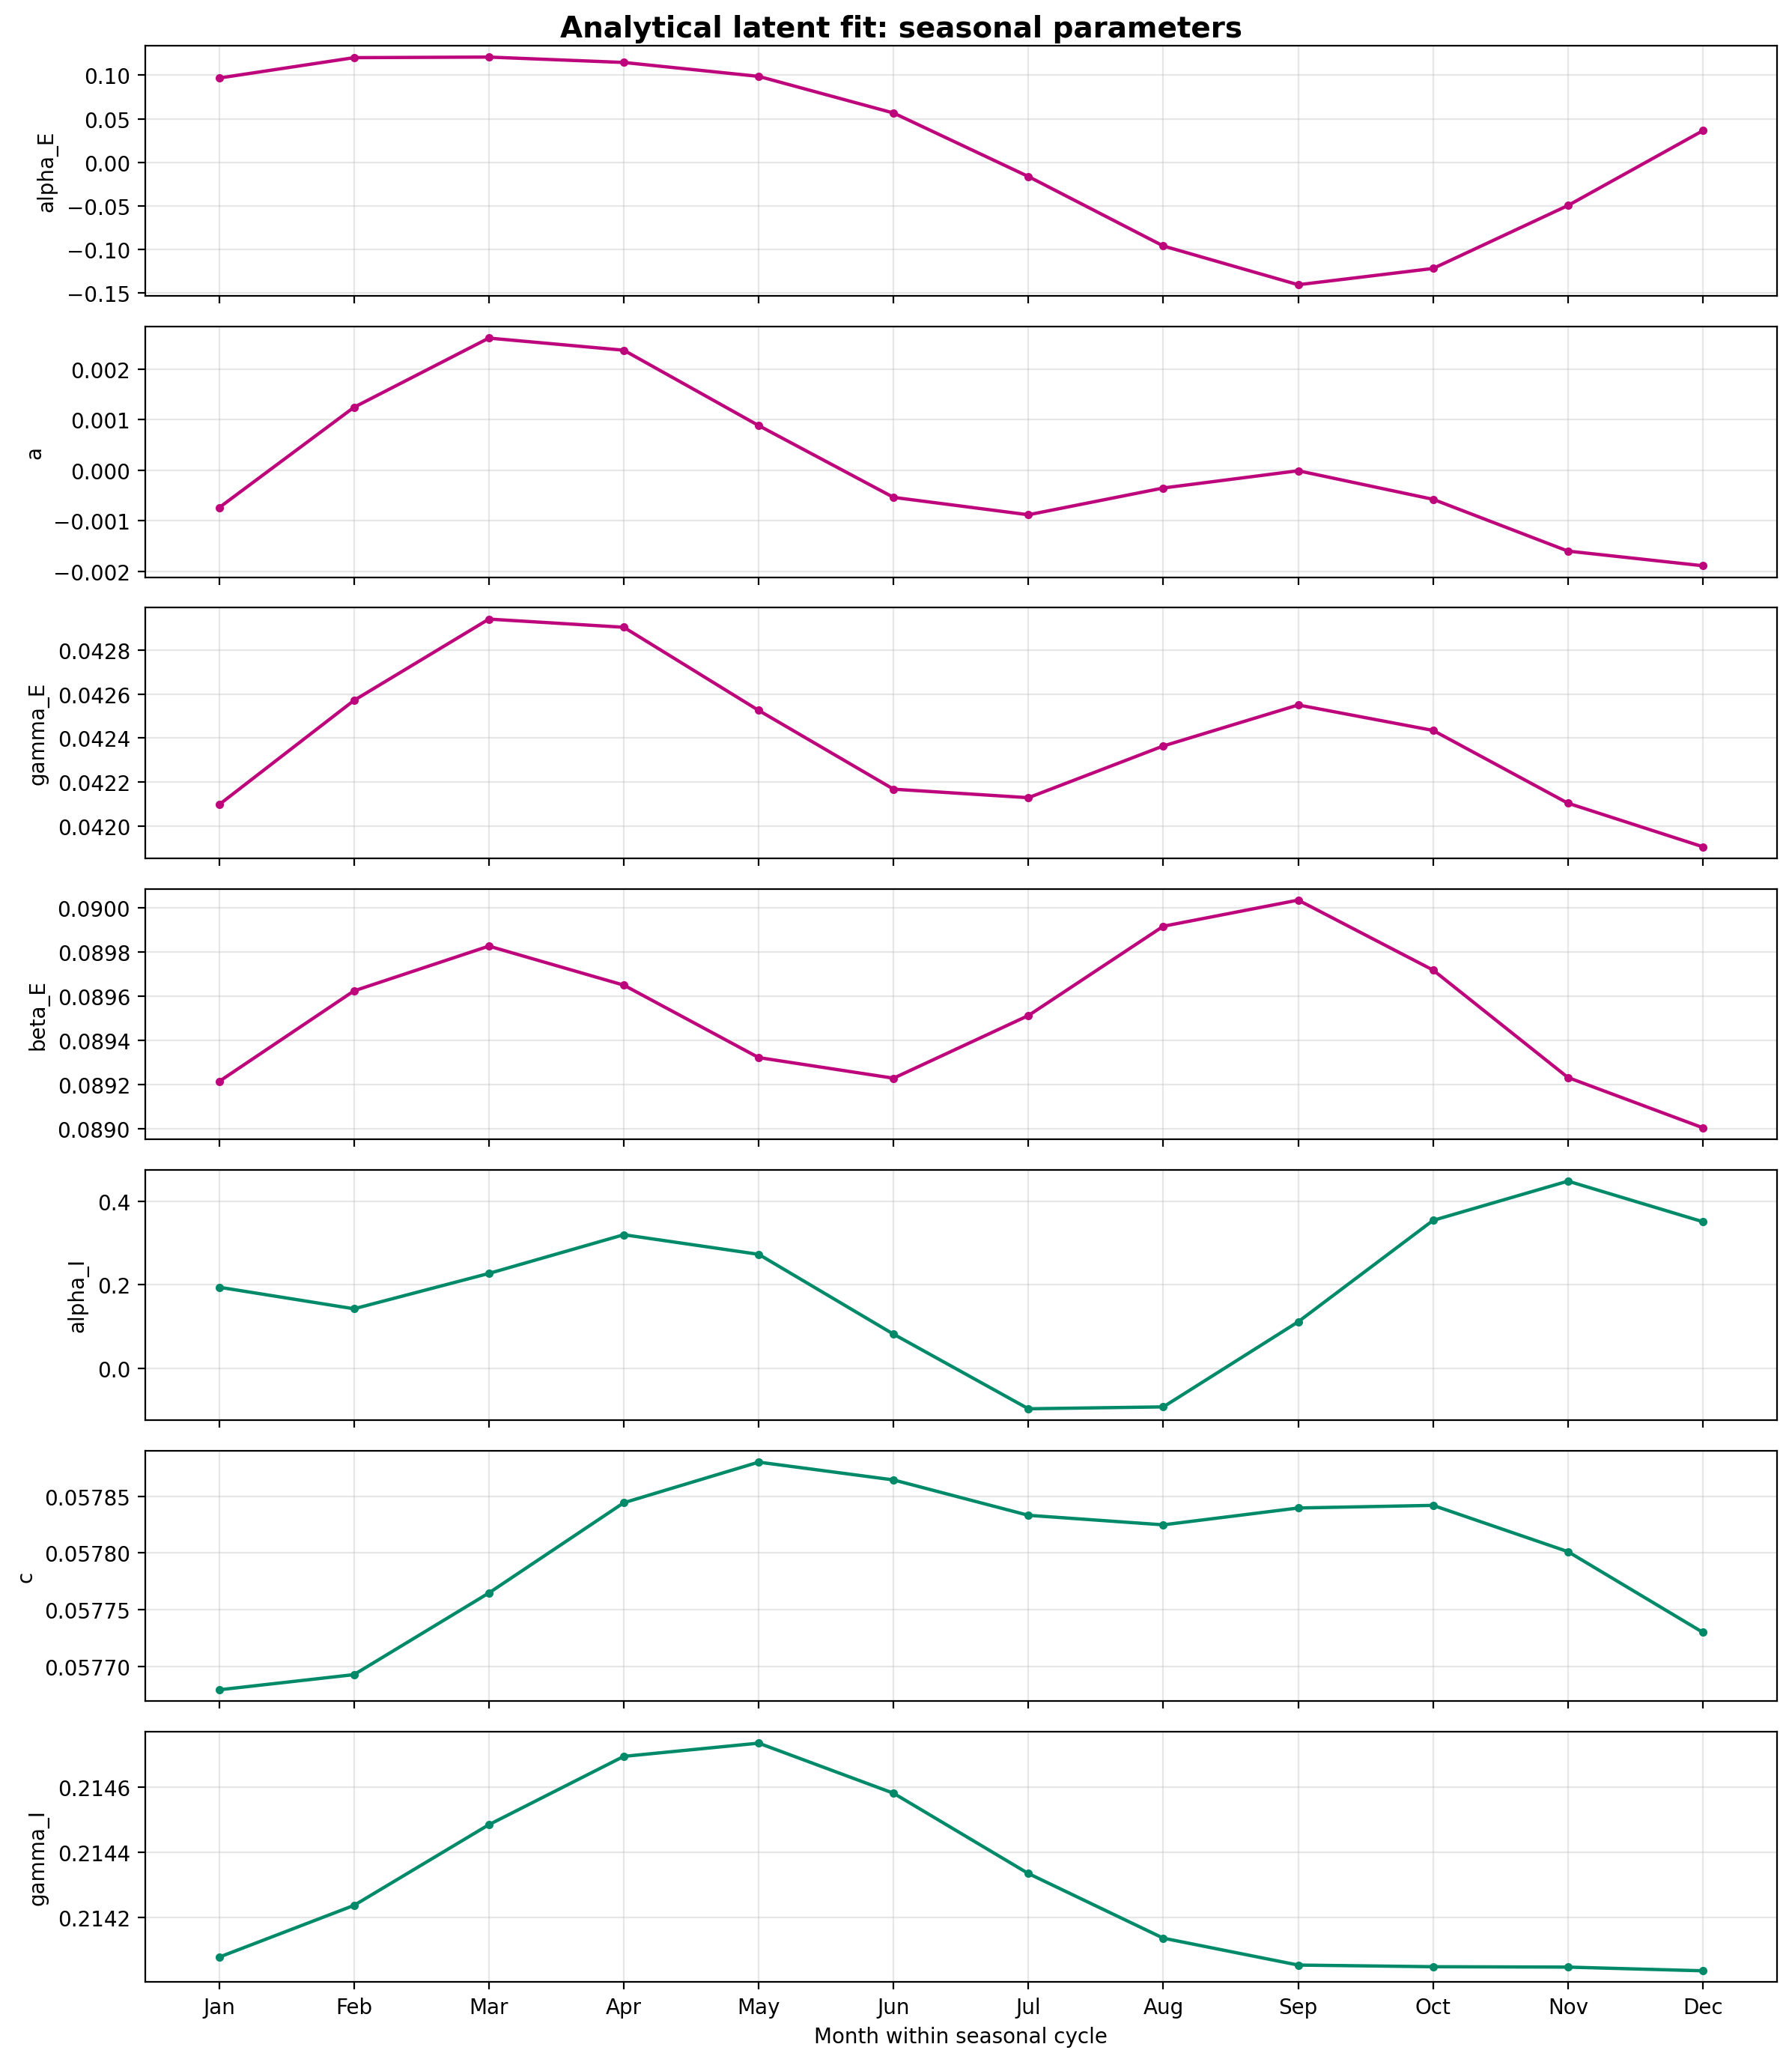

In [7]:
fig, axes = pl.plot_seasonal_parameters(model.params, title="Analytical latent fit: seasonal parameters")

## 4. Free-run ensembles

`noise_scale` was calibrated in `fit()` so the ensemble's mean std of E and I matches the observations. Each member starts from a jittered first Kalman state.

In [8]:
print("calibrated process-noise scale:", round(model.noise_scale, 4))
ens = model.freerun_ensemble(n_members=100, x0_jitter_scale=0.05, seed=13)   # (members, time, 5)

months, years = model.months, model.time.year.values
pd.concat([dg.std_autocorr_table(E_obs, ens, "E", "direct"),
           dg.std_autocorr_table(I_obs, ens, "I", "direct")]).round(4).reset_index(drop=True)

calibrated process-noise scale: 0.7985


,label,var,obs_std,model_std_mean,model_std_std,obs_acf1,model_acf1_mean,model_acf1_std
0,direct,E,0.8151,0.8473,0.1059,0.9587,0.9612,0.0061
1,direct,I,0.4390,0.3960,0.0228,0.8071,0.8433,0.0172


In [9]:
# Sanity check: if a model curve is missing in the plots below, look here first.
print("ensemble:", dg.ensemble_health(ens))
print("params  :", {k: round(v, 3) if isinstance(v, float) else v for k, v in dg.parameter_health(model.params).items()})

ensemble: {'n_members': 100, 'n_nonfinite': 0, 'n_exploded': 0, 'n_flat': 0, 'max_abs_E_or_I': 4.399168952949306}
params  : {'min_alpha_E': -0.14, 'min_alpha_I': -0.097, 'min_gamma_E': 0.042, 'min_gamma_I': 0.214, 'growth_100yr': 0.0, 'finite': True}


In [10]:
print("E peak-month locking (December):",
      dg.month_locking_score(dg.peak_months_ensemble(ens, "E", min_abs_peak=1.0, start_month=model.start_month), 11))
pd.Series(dg.ensemble_mean_std(ens)).round(4).to_frame("mean std").T

E peak-month locking (December): 0.5


,E_I,E_D,I_I,I_D,h,E_total,I_total
mean std,0.8546,0.2437,0.3497,0.1853,1.0294,0.8473,0.396


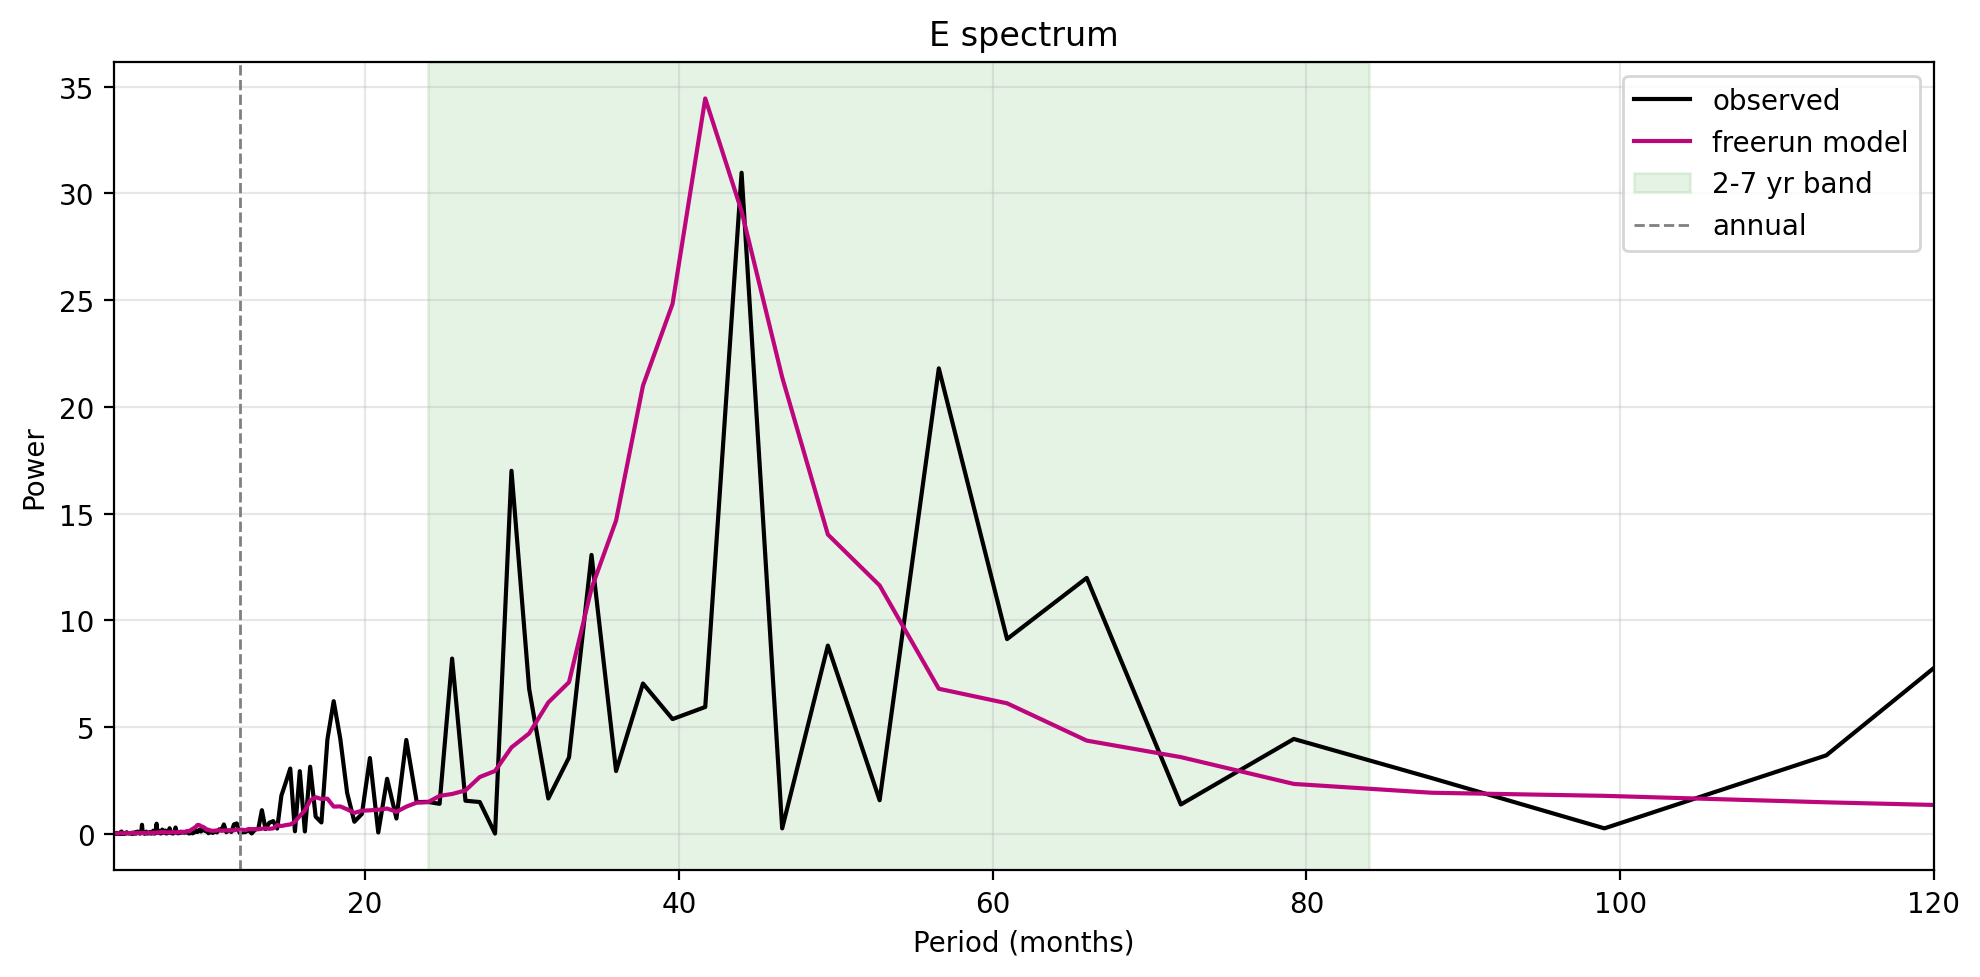

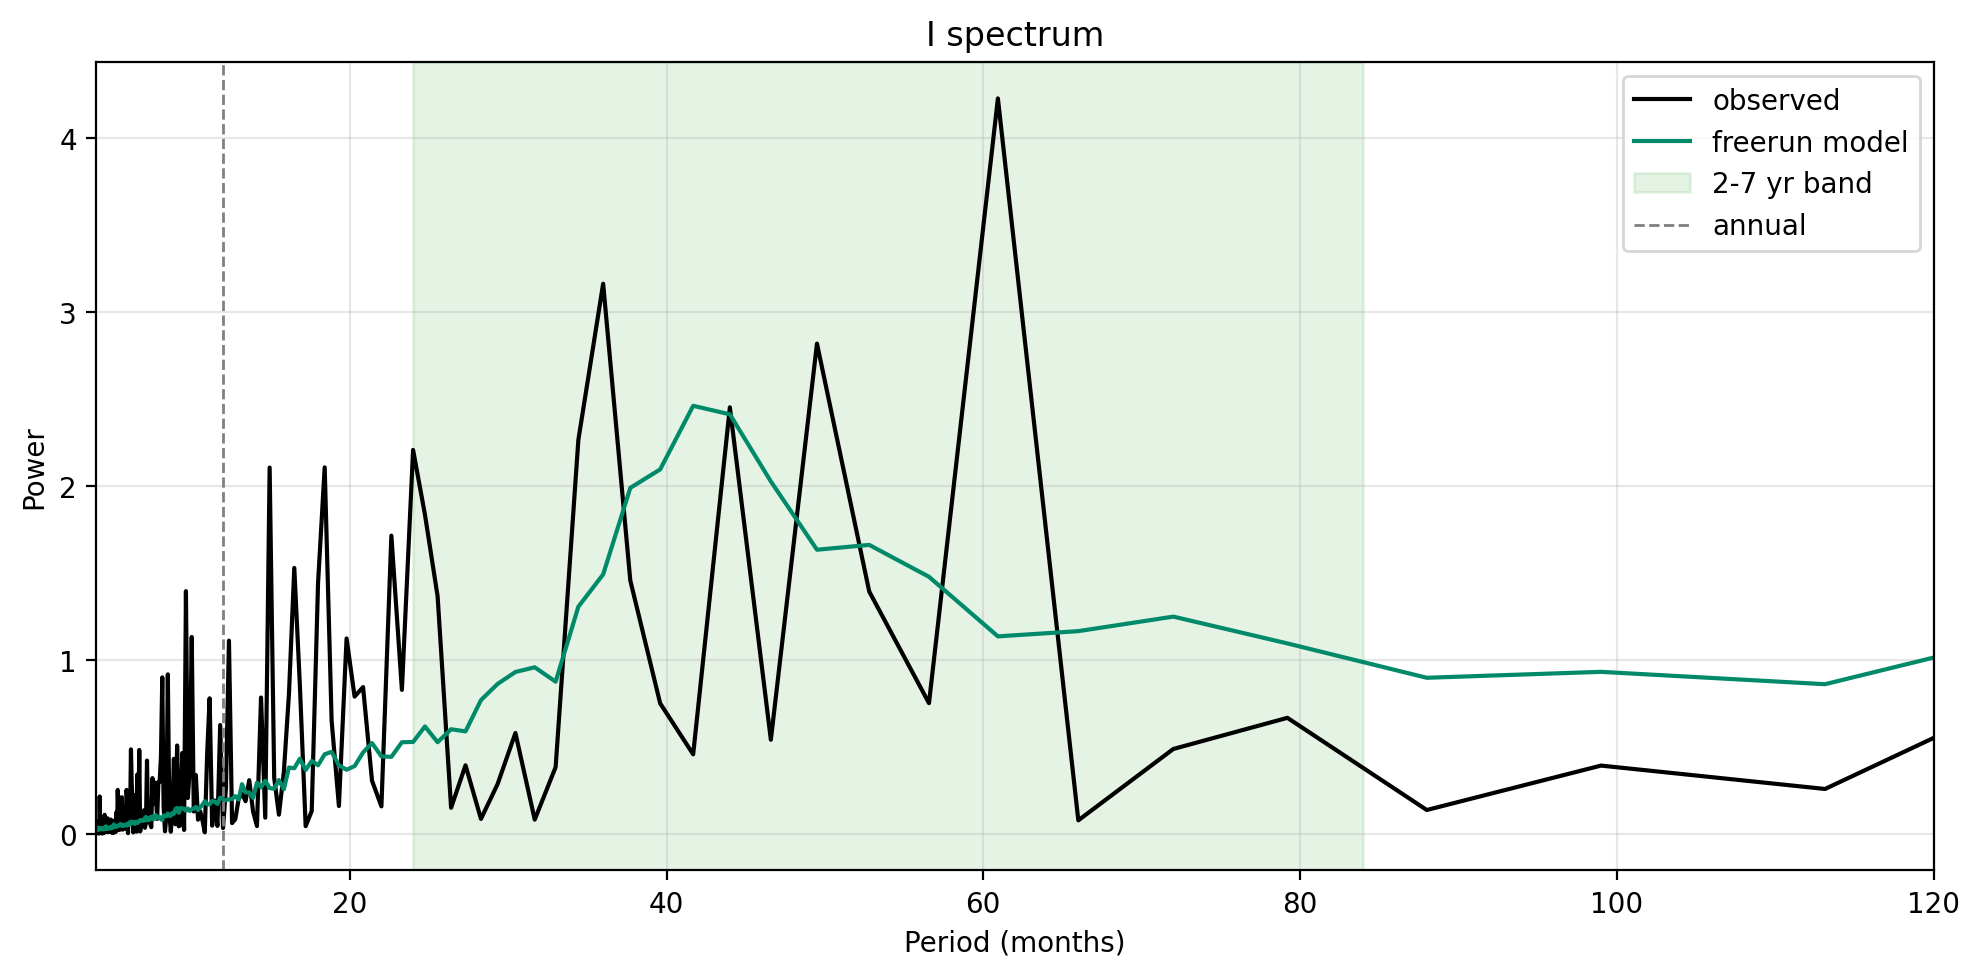

In [11]:
for var in "EI":
    pl.plot_spectrum_compare(dg.spectrum_compare(model.obs(var), ens, var), var)

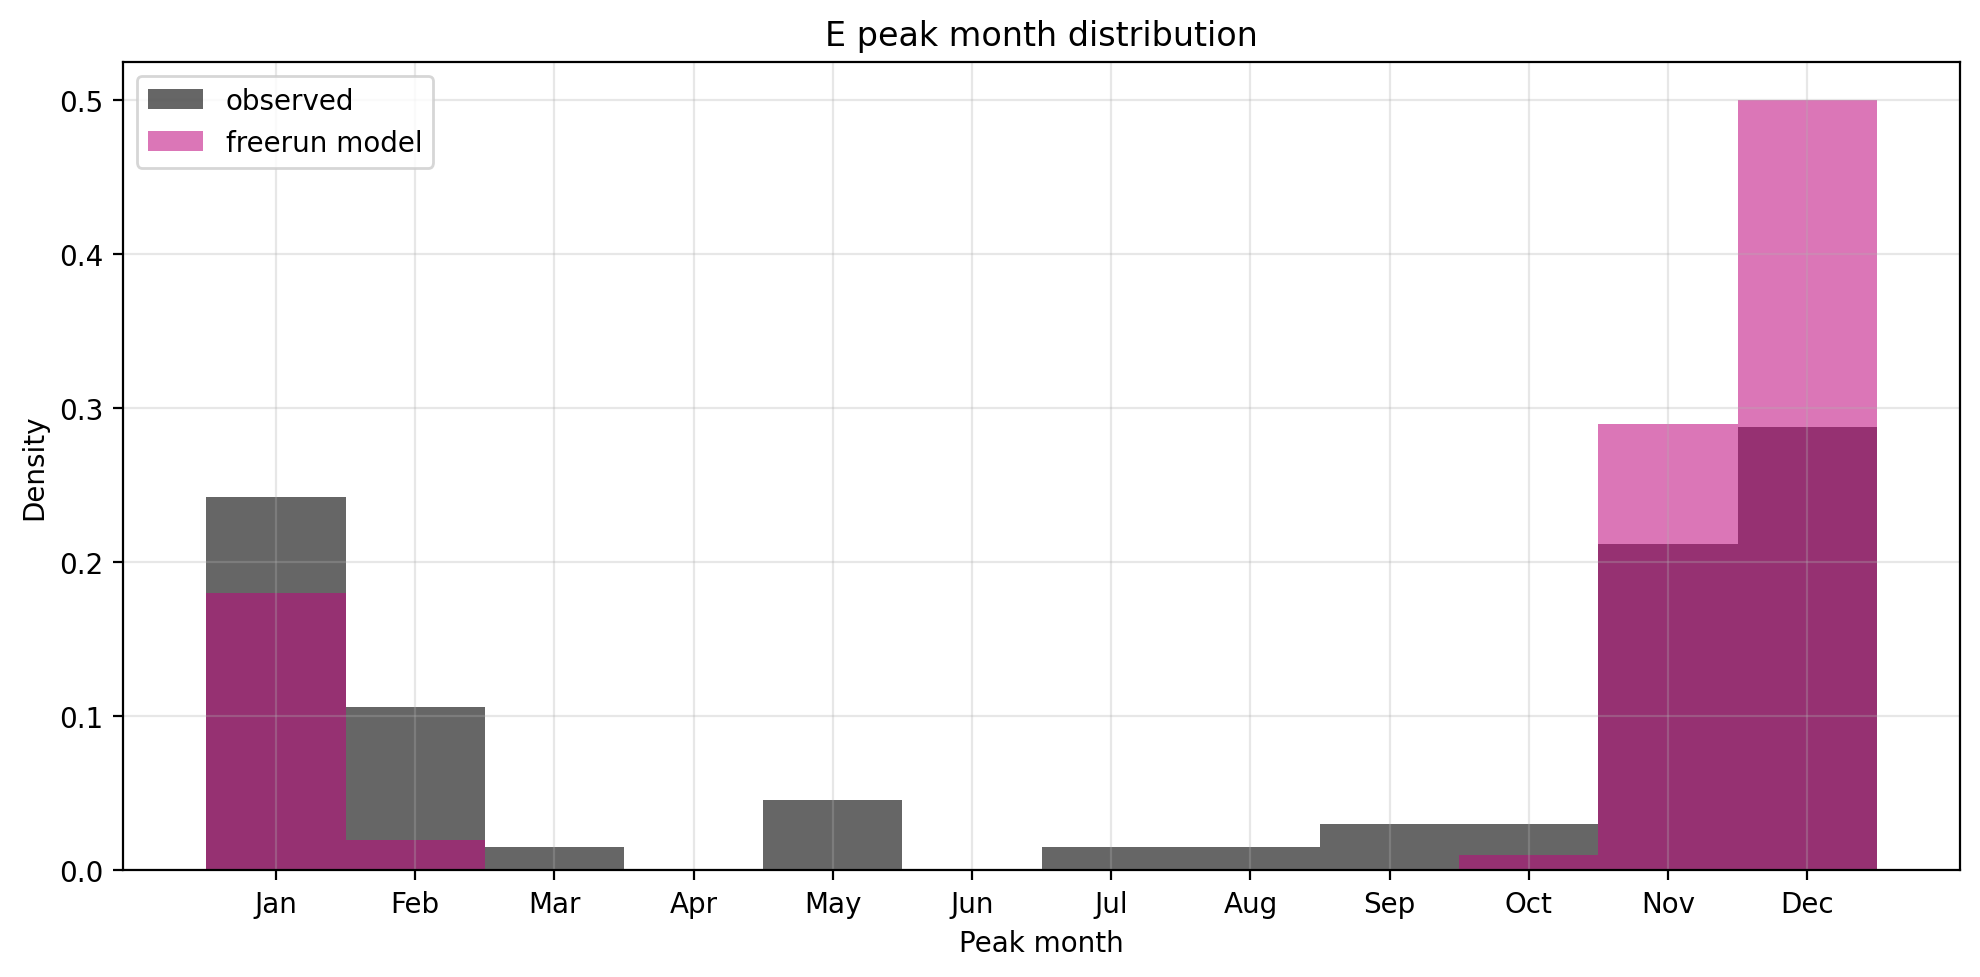

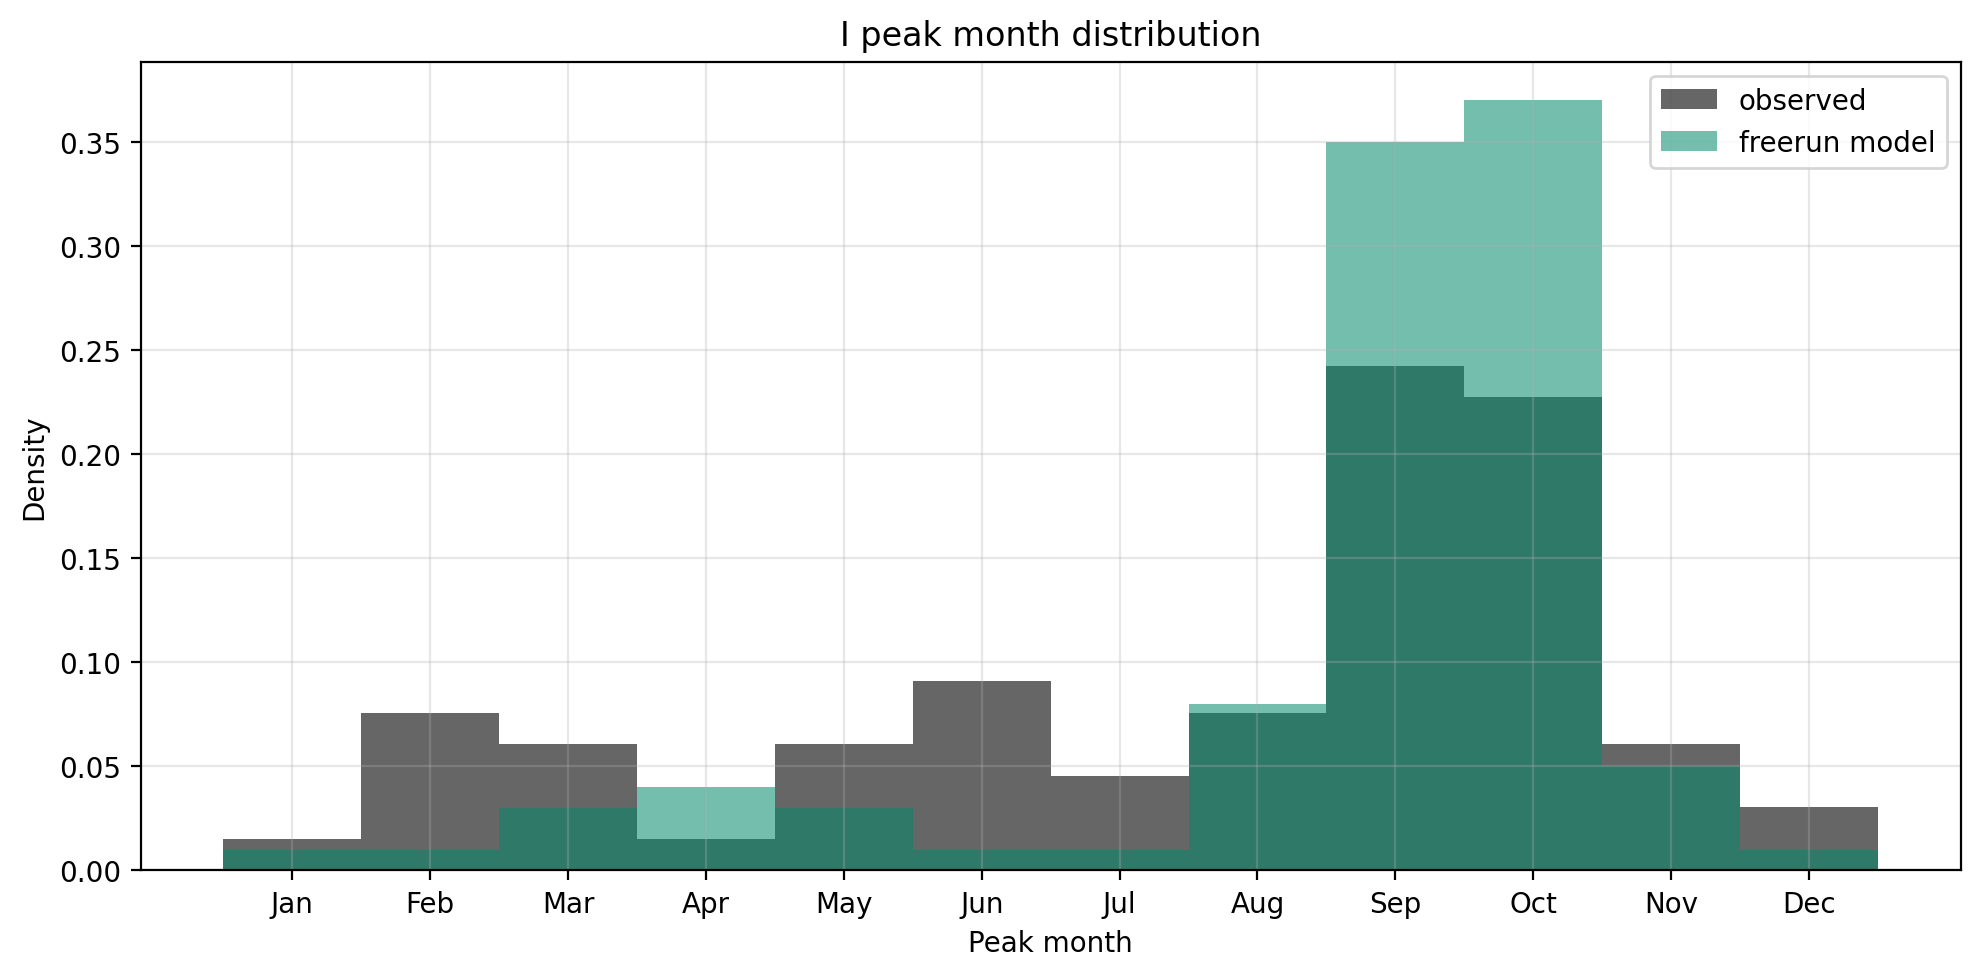

In [12]:
for var in "EI":
    obs_pk = model.observed_peak_months(var, min_abs_peak=0.01)
    mod_pk = dg.peak_months_ensemble(ens, var, min_abs_peak=0.01, start_month=model.start_month)
    pl.plot_peak_month_histogram(obs_pk, mod_pk, var)

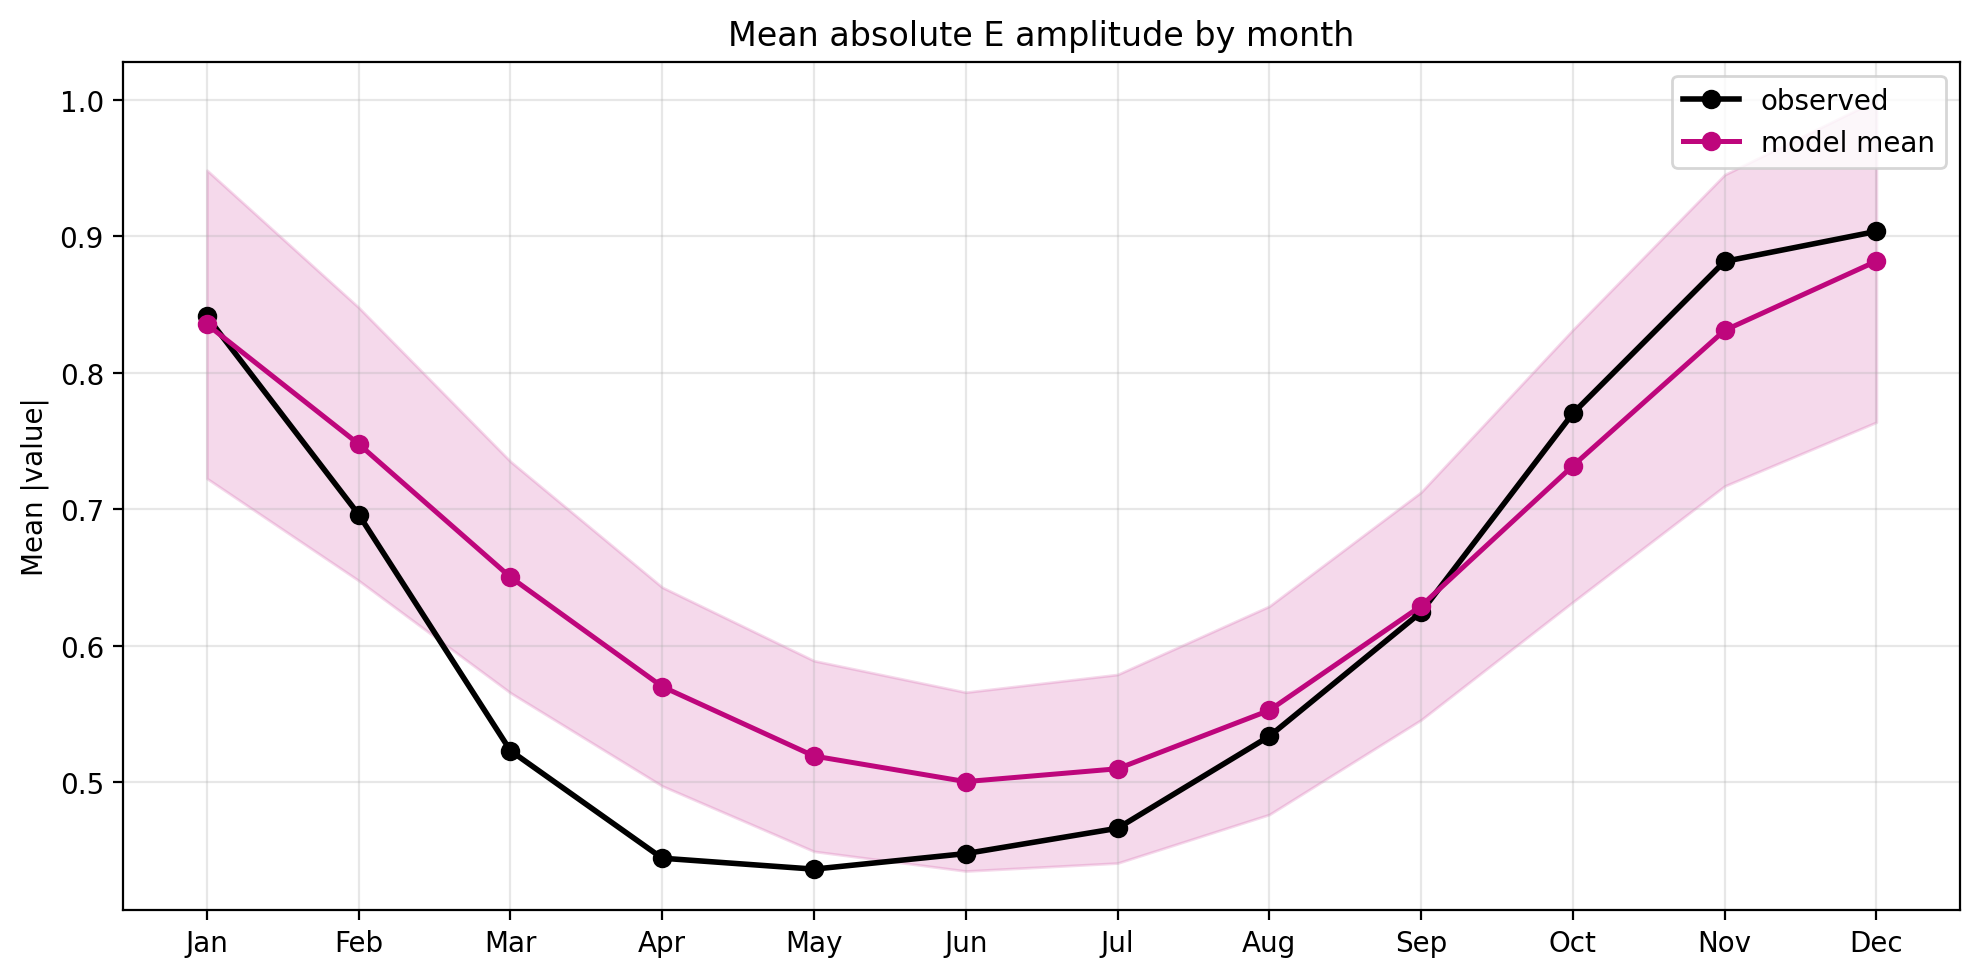

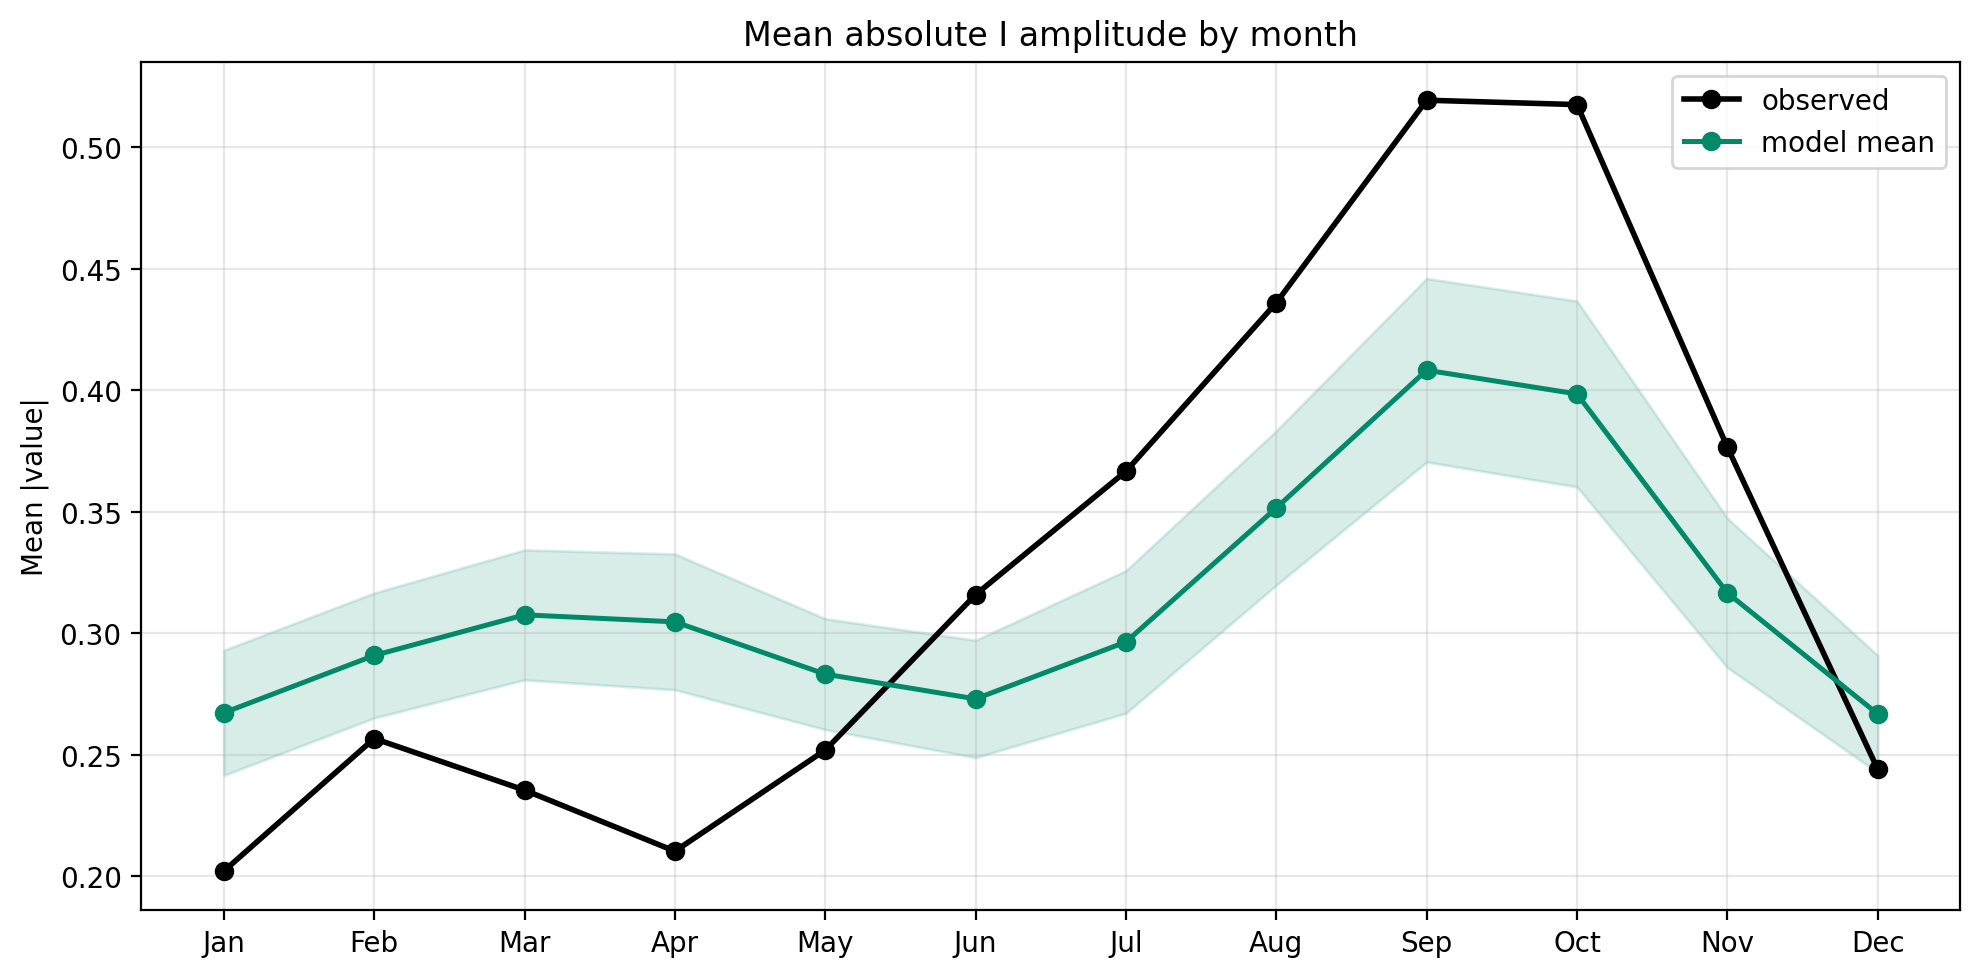

In [13]:
for var in "EI":
    m, s = dg.ensemble_monthly_abs_amplitude(ens, months, var)
    pl.plot_monthly_abs_amplitude(dg.monthly_abs_amplitude(model.obs(var), months), m, s, var)

## 5. Hindcast skill (in-sample)

Re-initialise the model from the Kalman state at *every* month, integrate up to 24 months ahead, and verify against the observations. A single call produces both E and I for all leads, and the same object feeds the lead-time curves and the seasonality heat-maps. Everything is in-sample, and the persistence baseline uses the same start dates.

,model_E_corr,model_E_rmse,persistence_E_corr,persistence_E_rmse,model_I_corr,model_I_rmse,persistence_I_corr,persistence_I_rmse
lead,,,,,,,,
0,0.998,0.048,1.000,0.000,1.000,0.005,1.000,0.000
2,0.905,0.350,0.873,0.406,0.594,0.353,0.557,0.402
4,0.773,0.538,0.646,0.678,0.285,0.432,0.217,0.535
6,0.646,0.673,0.393,0.889,0.139,0.451,0.081,0.579
8,0.531,0.797,0.158,1.047,0.078,0.459,-0.007,0.607
10,0.451,0.907,-0.002,1.143,0.100,0.456,-0.060,0.623
12,0.400,0.992,-0.083,1.189,0.122,0.456,-0.074,0.627
14,0.358,1.055,-0.125,1.213,0.131,0.461,-0.100,0.635
16,0.320,1.092,-0.157,1.229,0.132,0.467,-0.049,0.620


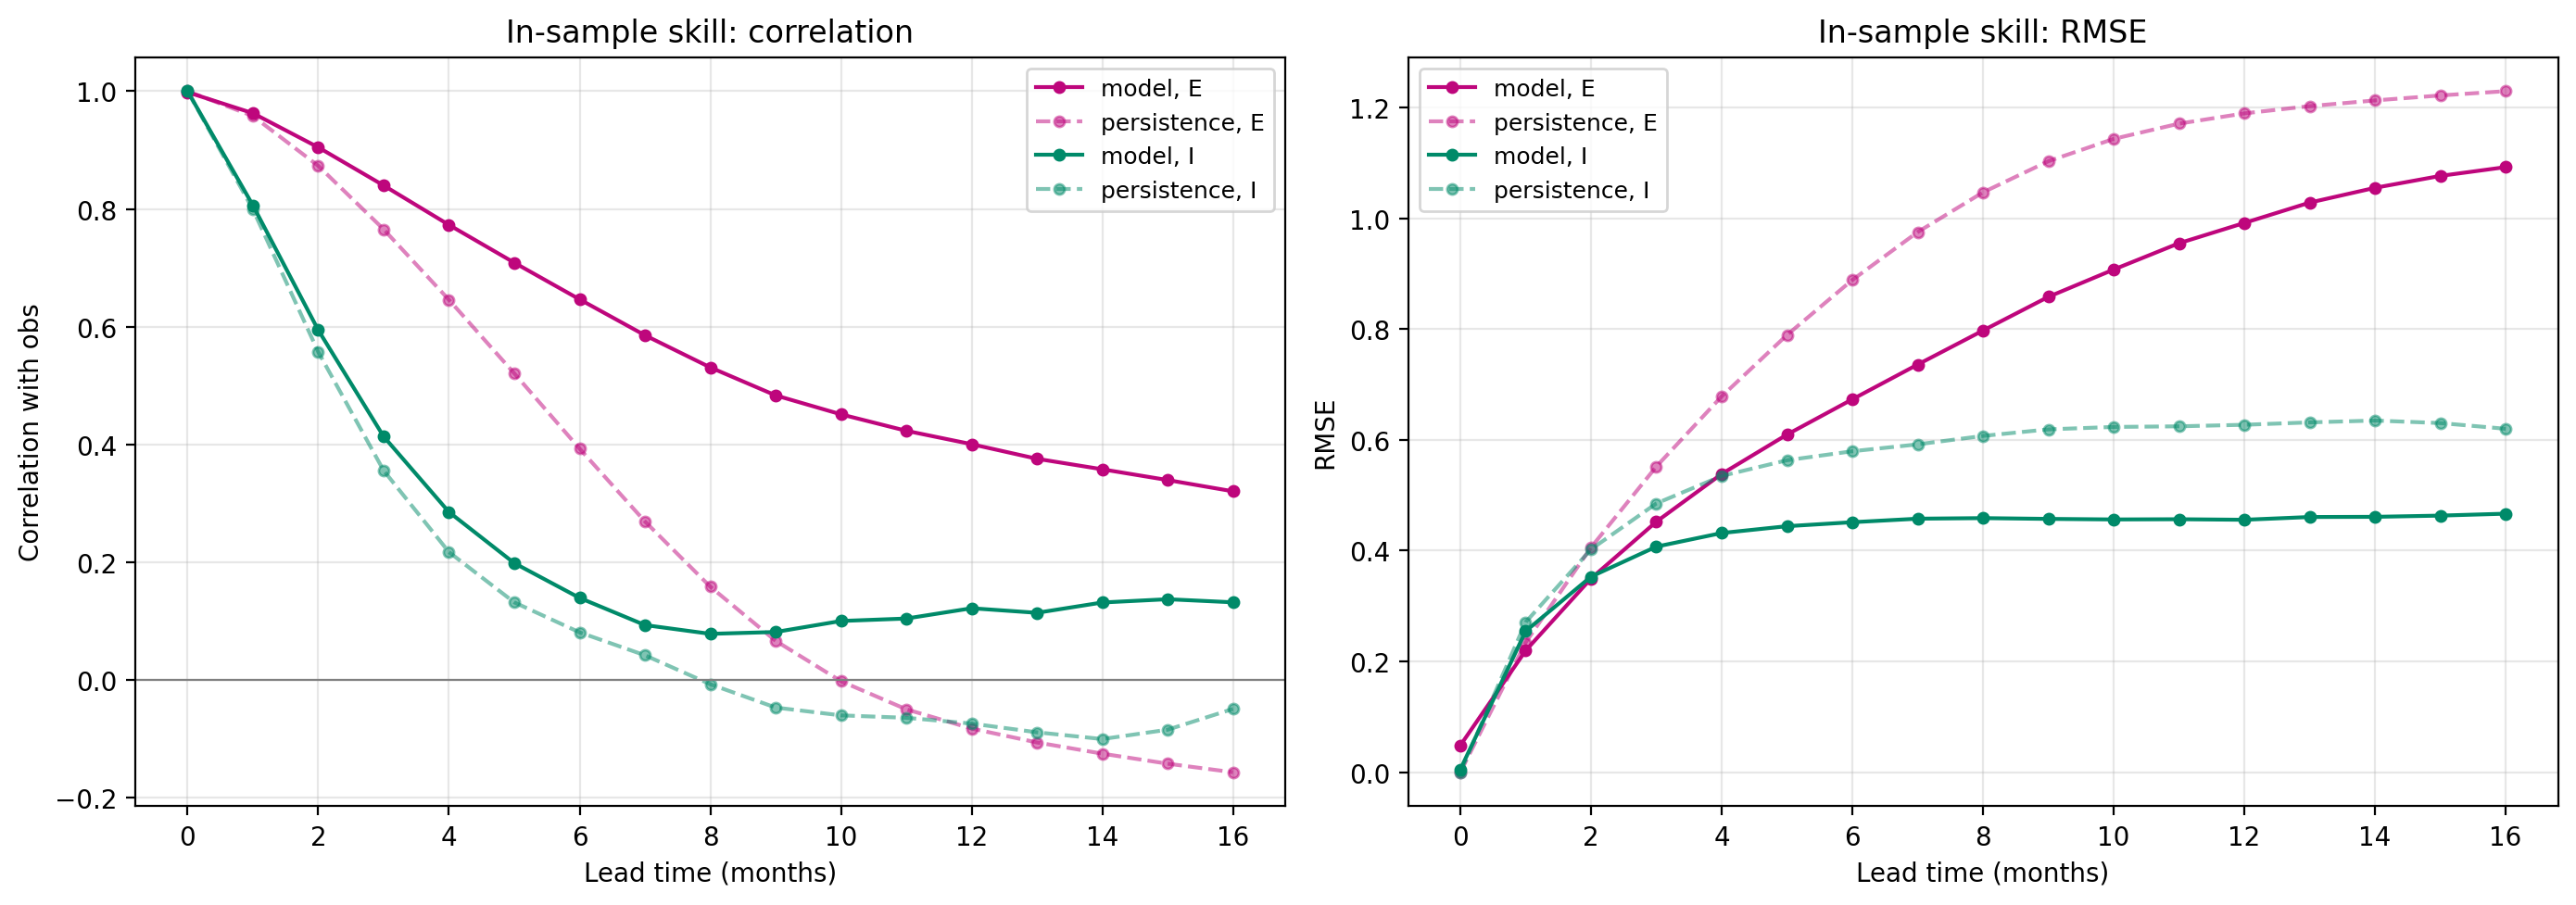

In [14]:
hc = model.hindcast(max_lead=24, n_members=20, x0_jitter_scale=0.05, seed=123)
pers = es.persistence_hindcasts(hc)

LEADS = 17     # plot leads 0-16 as in the original figure
skills = {}
for var in "EI":
    for name, h in (("model", hc), ("persistence", pers)):
        c, r = es.skill_by_lead(h, var)
        skills[f"{name}, {var}"] = (c[:LEADS], r[:LEADS])
fig, axes = pl.plot_skill_vs_lead(skills)

pd.DataFrame({
    "lead": np.arange(LEADS),
    **{f"{k.replace(', ', '_')}_{m}": v[i] for k, v in skills.items() for i, m in enumerate(("corr", "rmse"))},
}).round(3).set_index("lead").iloc[::2]

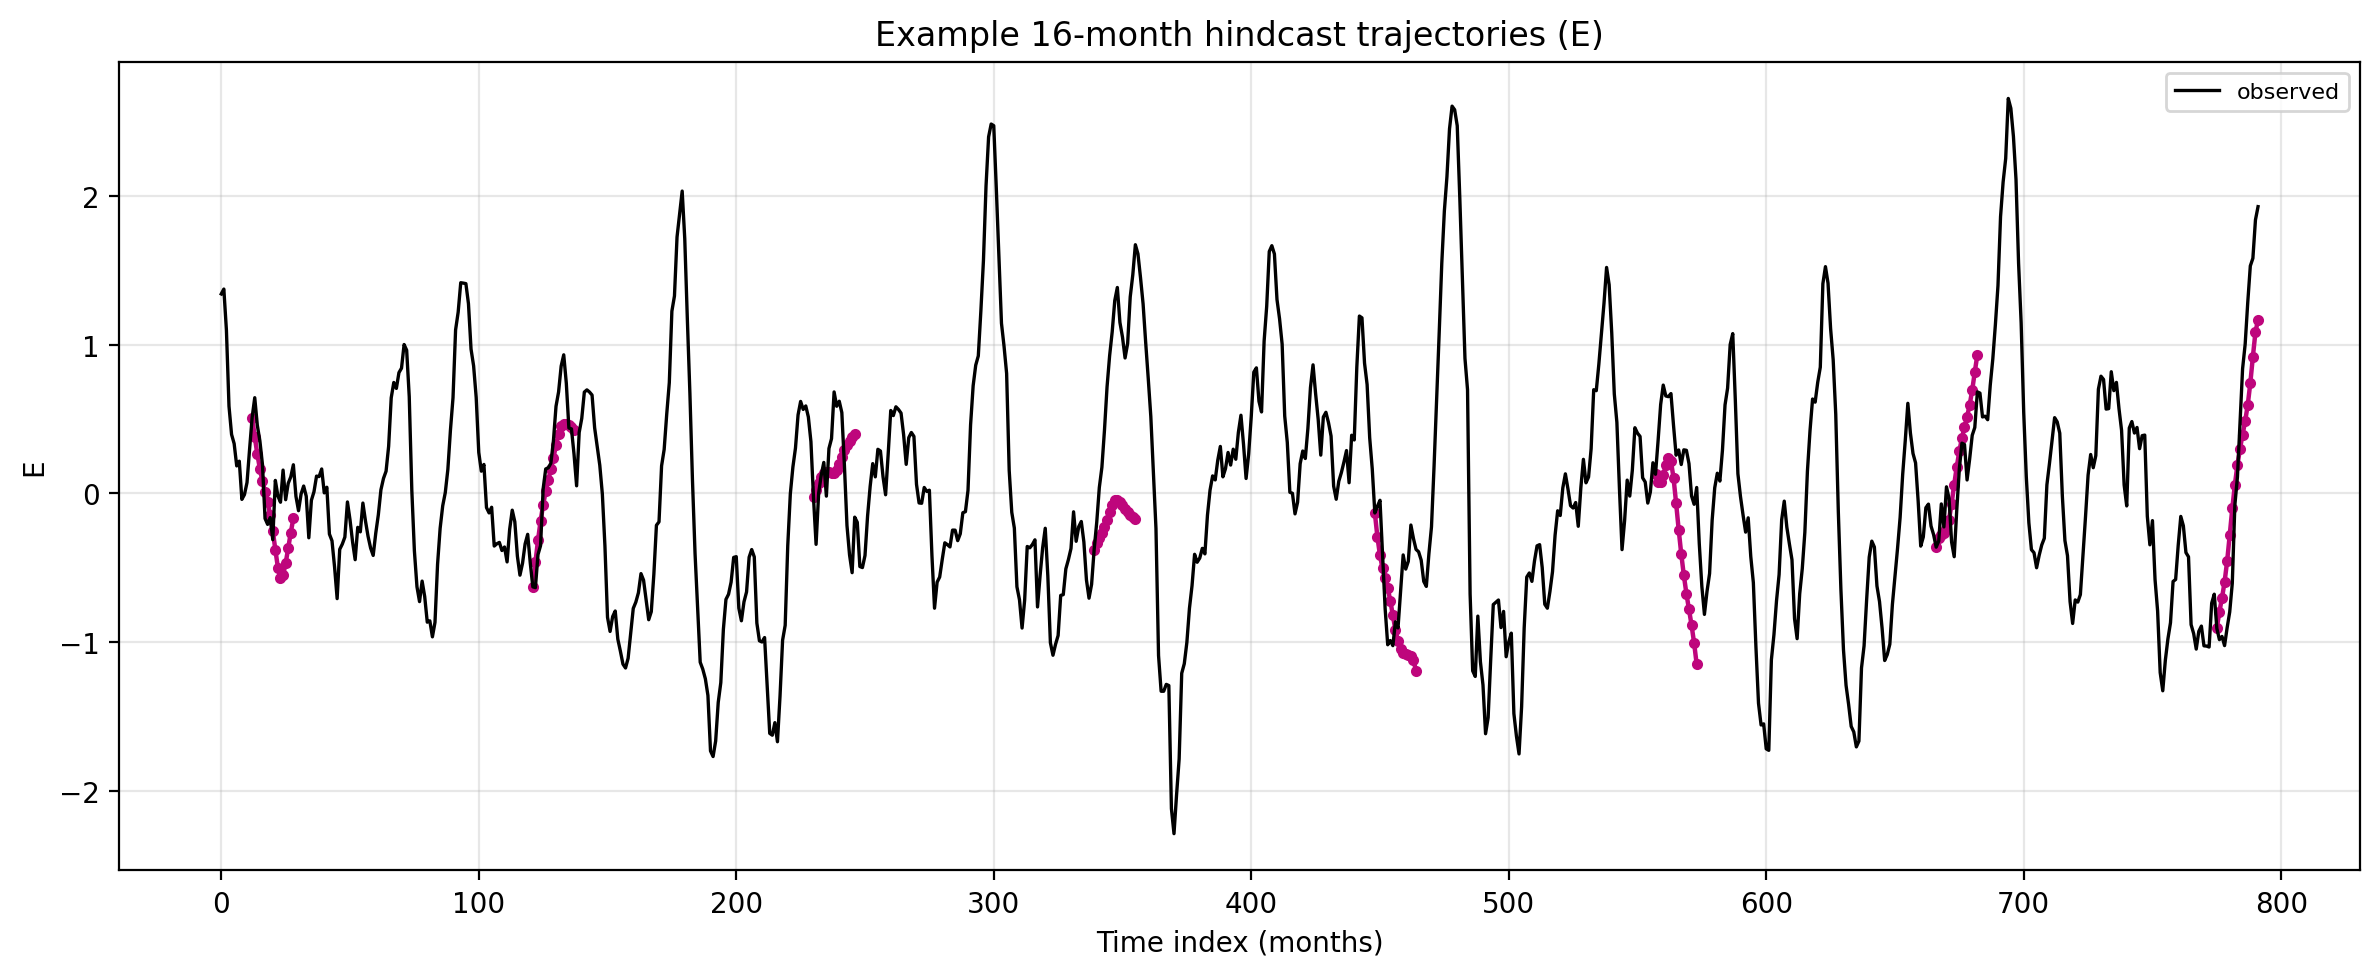

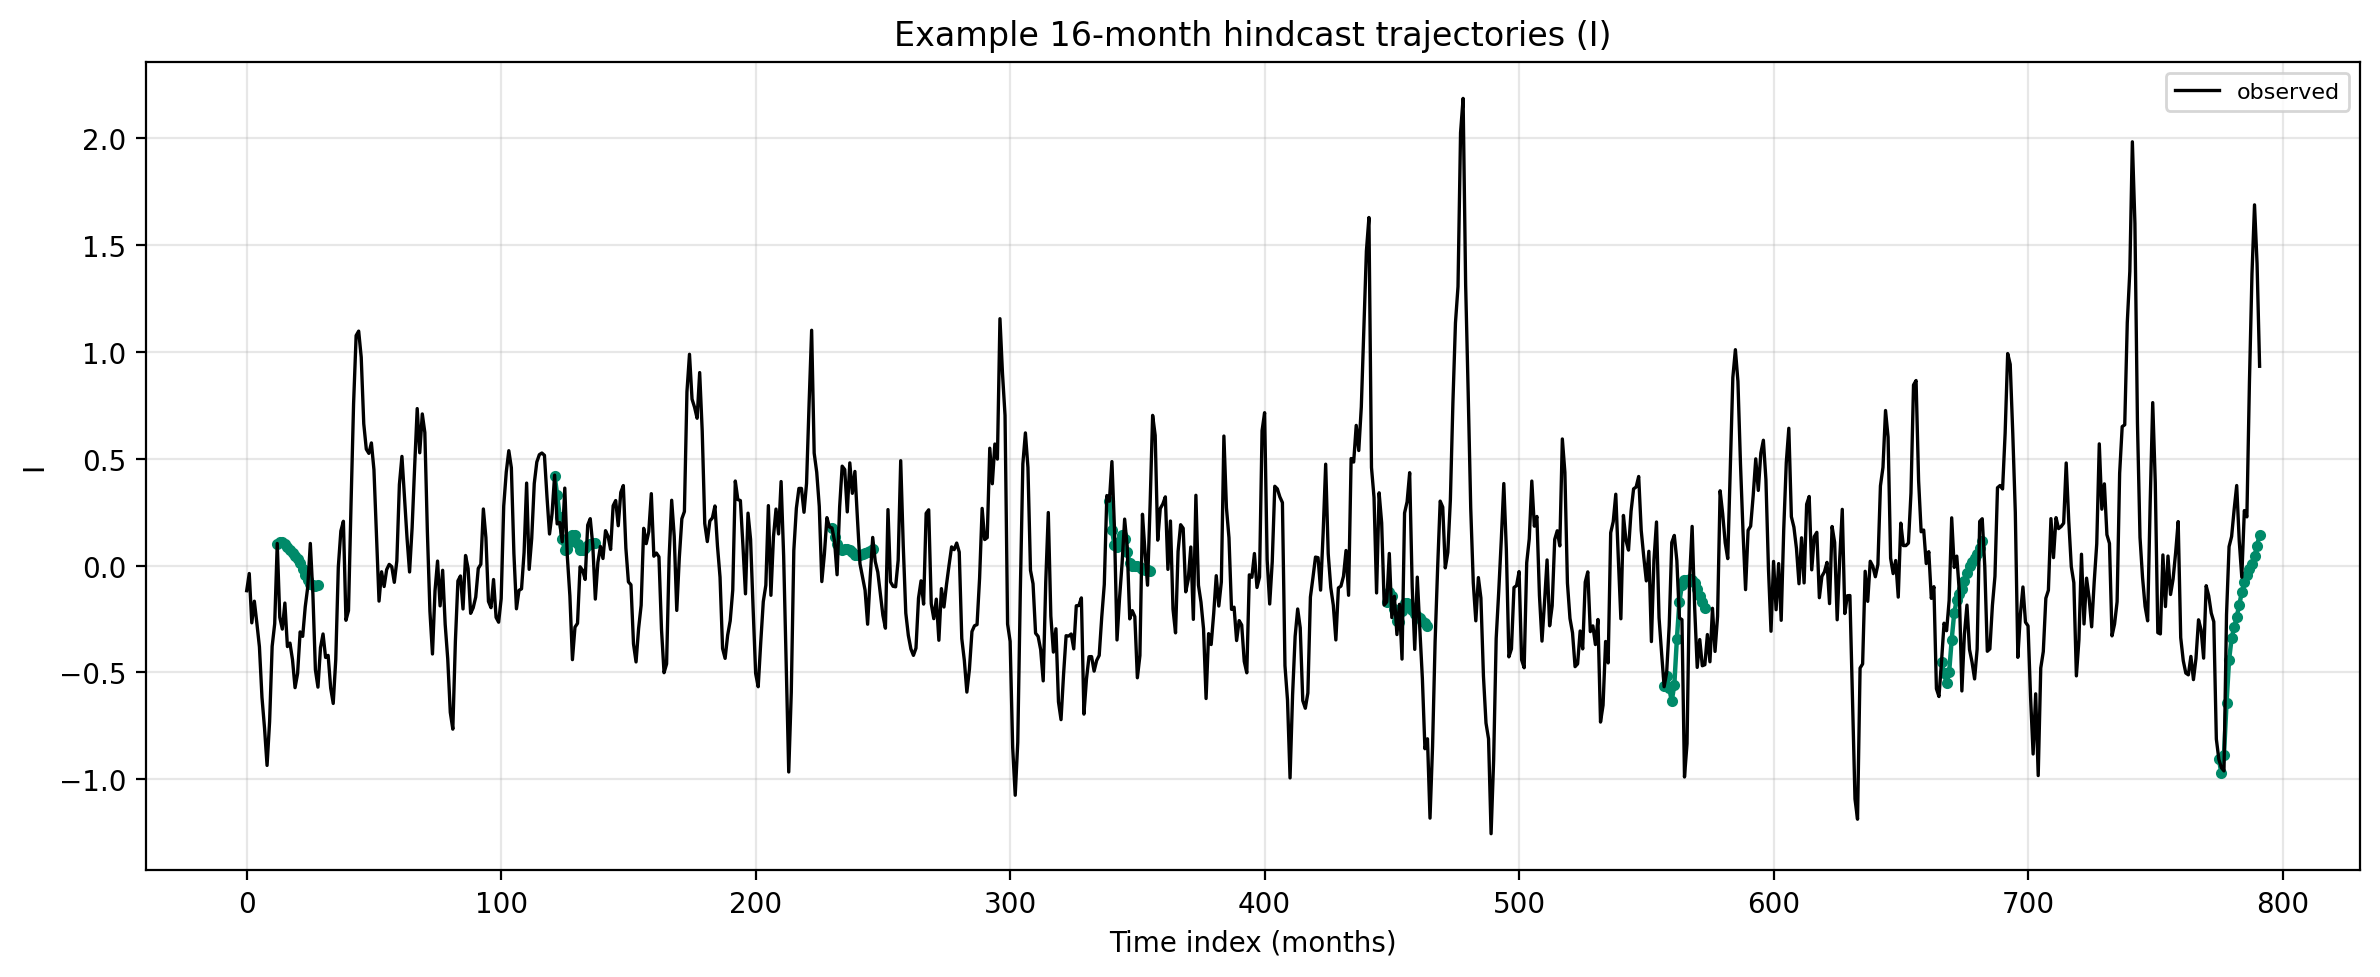

In [15]:
t0s = np.linspace(12, len(E_obs) - 17, 8, dtype=int)   # skip the zero-initialised first rows
for var in "EI":
    pl.plot_example_hindcasts(model.x_kalman, model.obs(var), model.params, model.months, t0s, var, max_lead=16)

## 6. One long free run (record + 80 years)

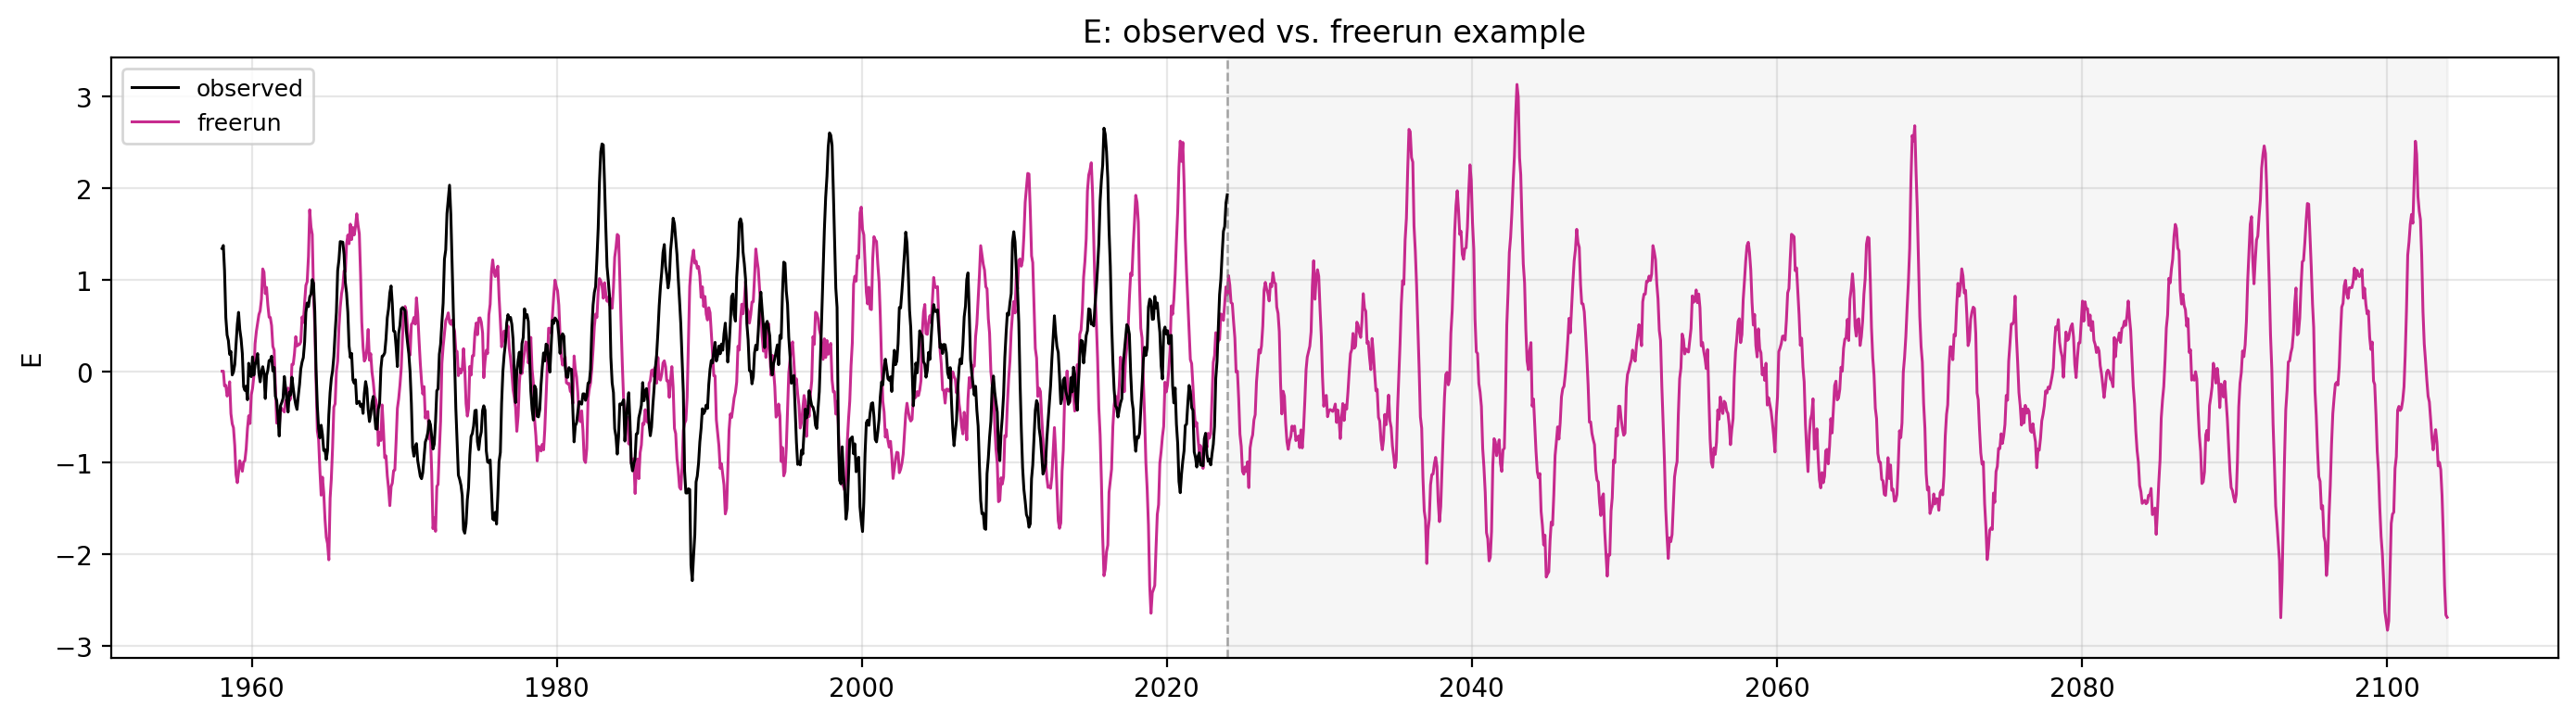

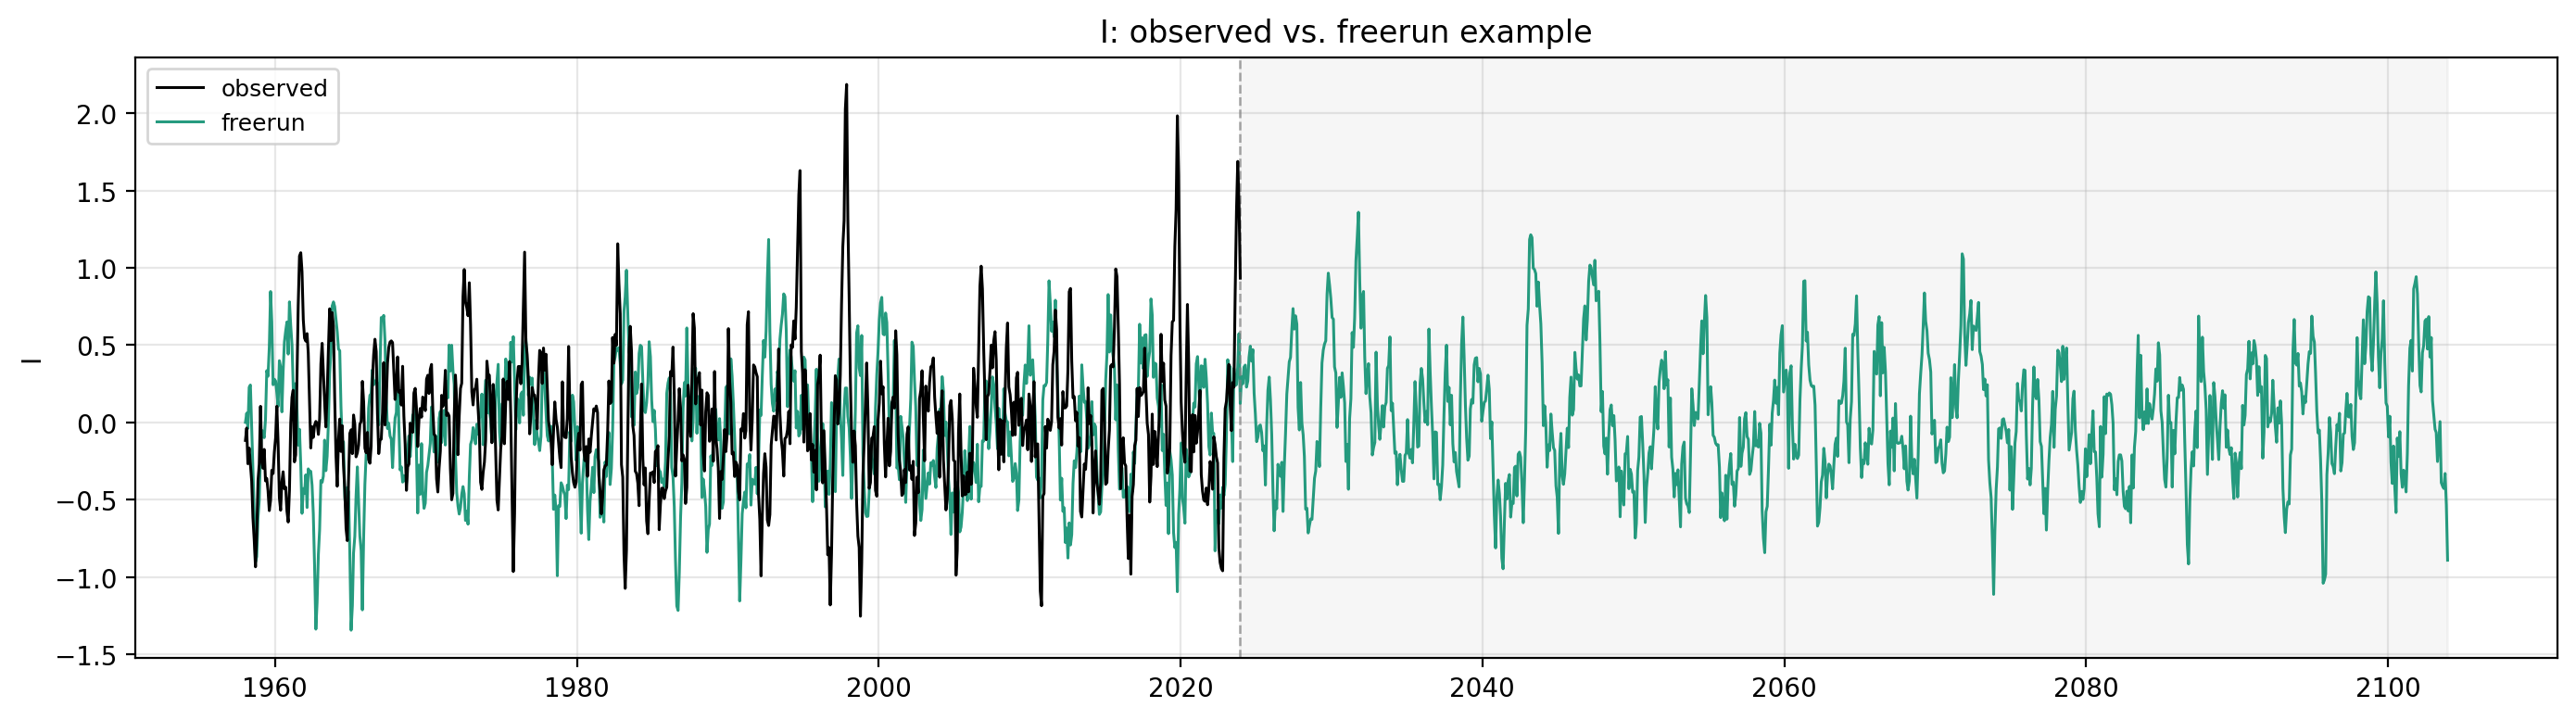

In [16]:
FUTURE_YEARS = 80
n_total = len(E_obs) + FUTURE_YEARS * 12
start = pd.Timestamp(model.time[0]).to_period("M").to_timestamp()
full_time = pd.date_range(start, periods=n_total, freq="MS") + pd.Timedelta(days=15)

x_long = model.simulate(n_total, seed=7, noise=True)
for var in "EI":
    pl.plot_freerun_timeline(model.time, model.obs(var), full_time, dg.state_total(x_long, var), var)

## 7. Seasonality of skill (initial month × target month)

Hatching marks correlations that are not significant at the 5 % level, using the Bretherton effective sample size.

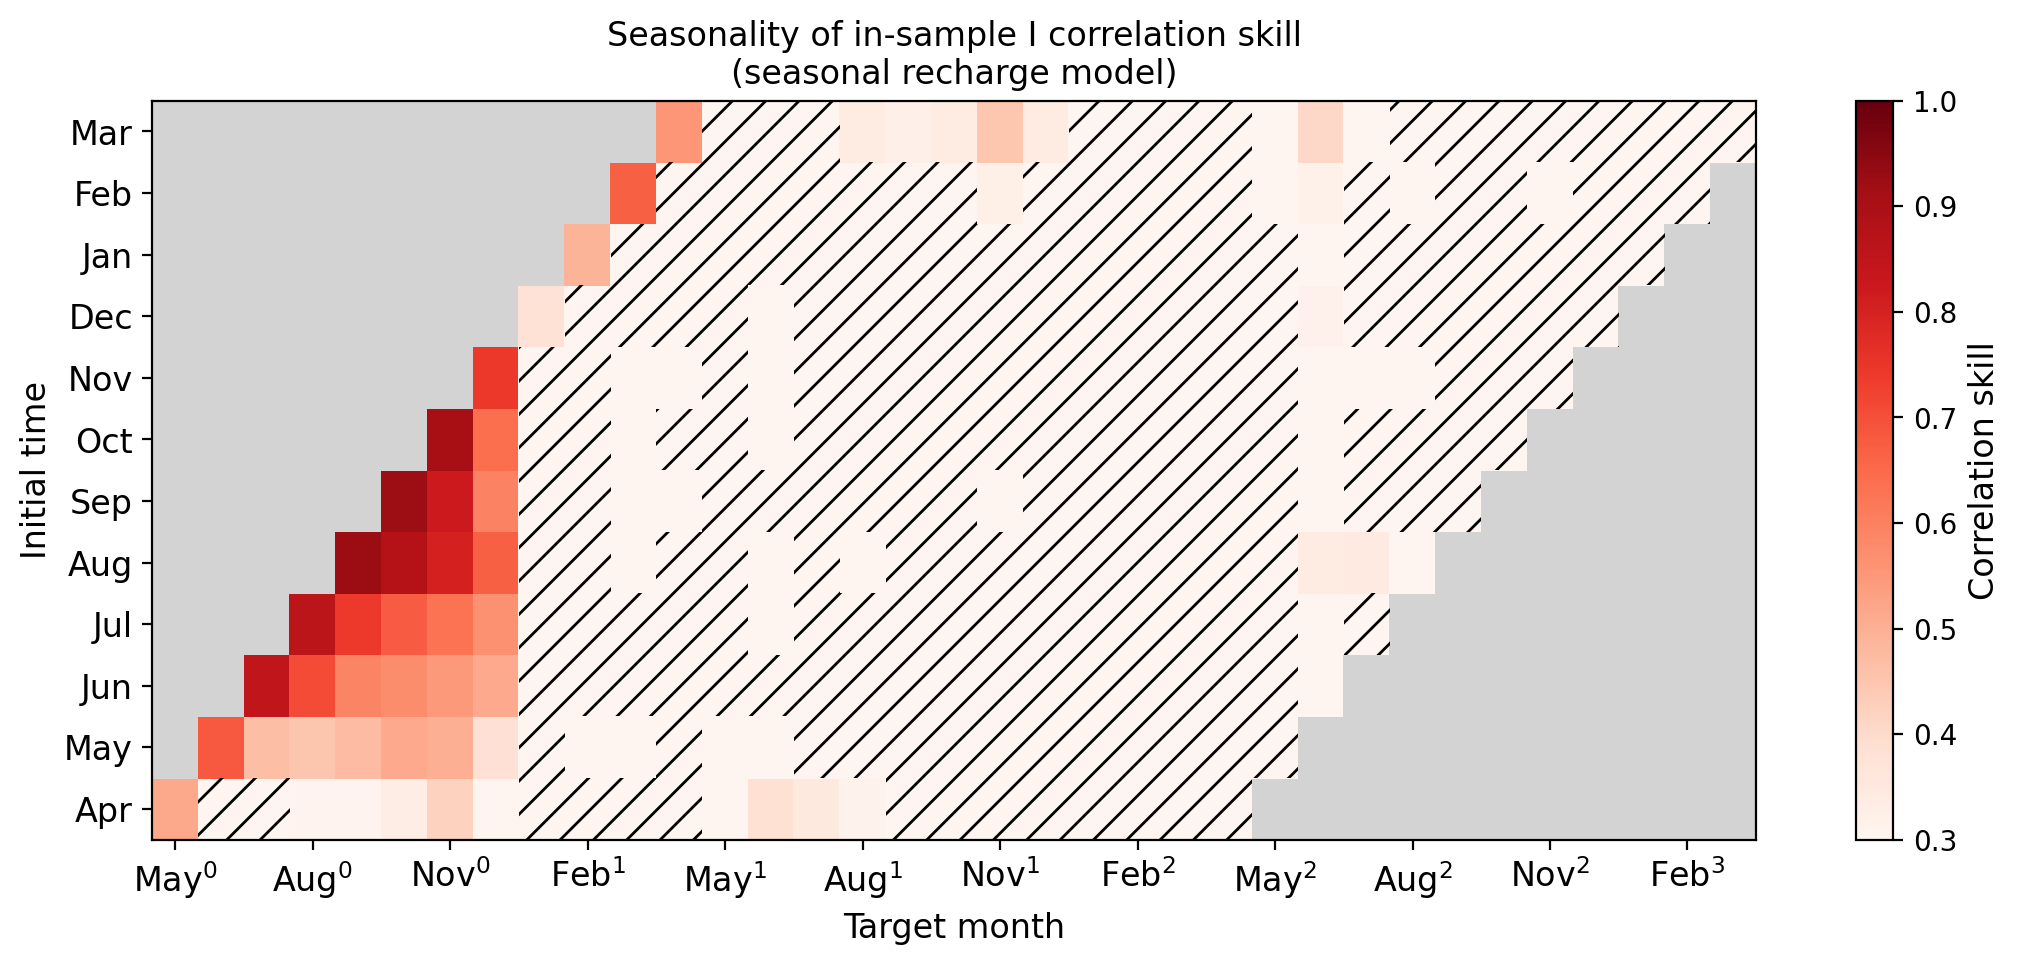

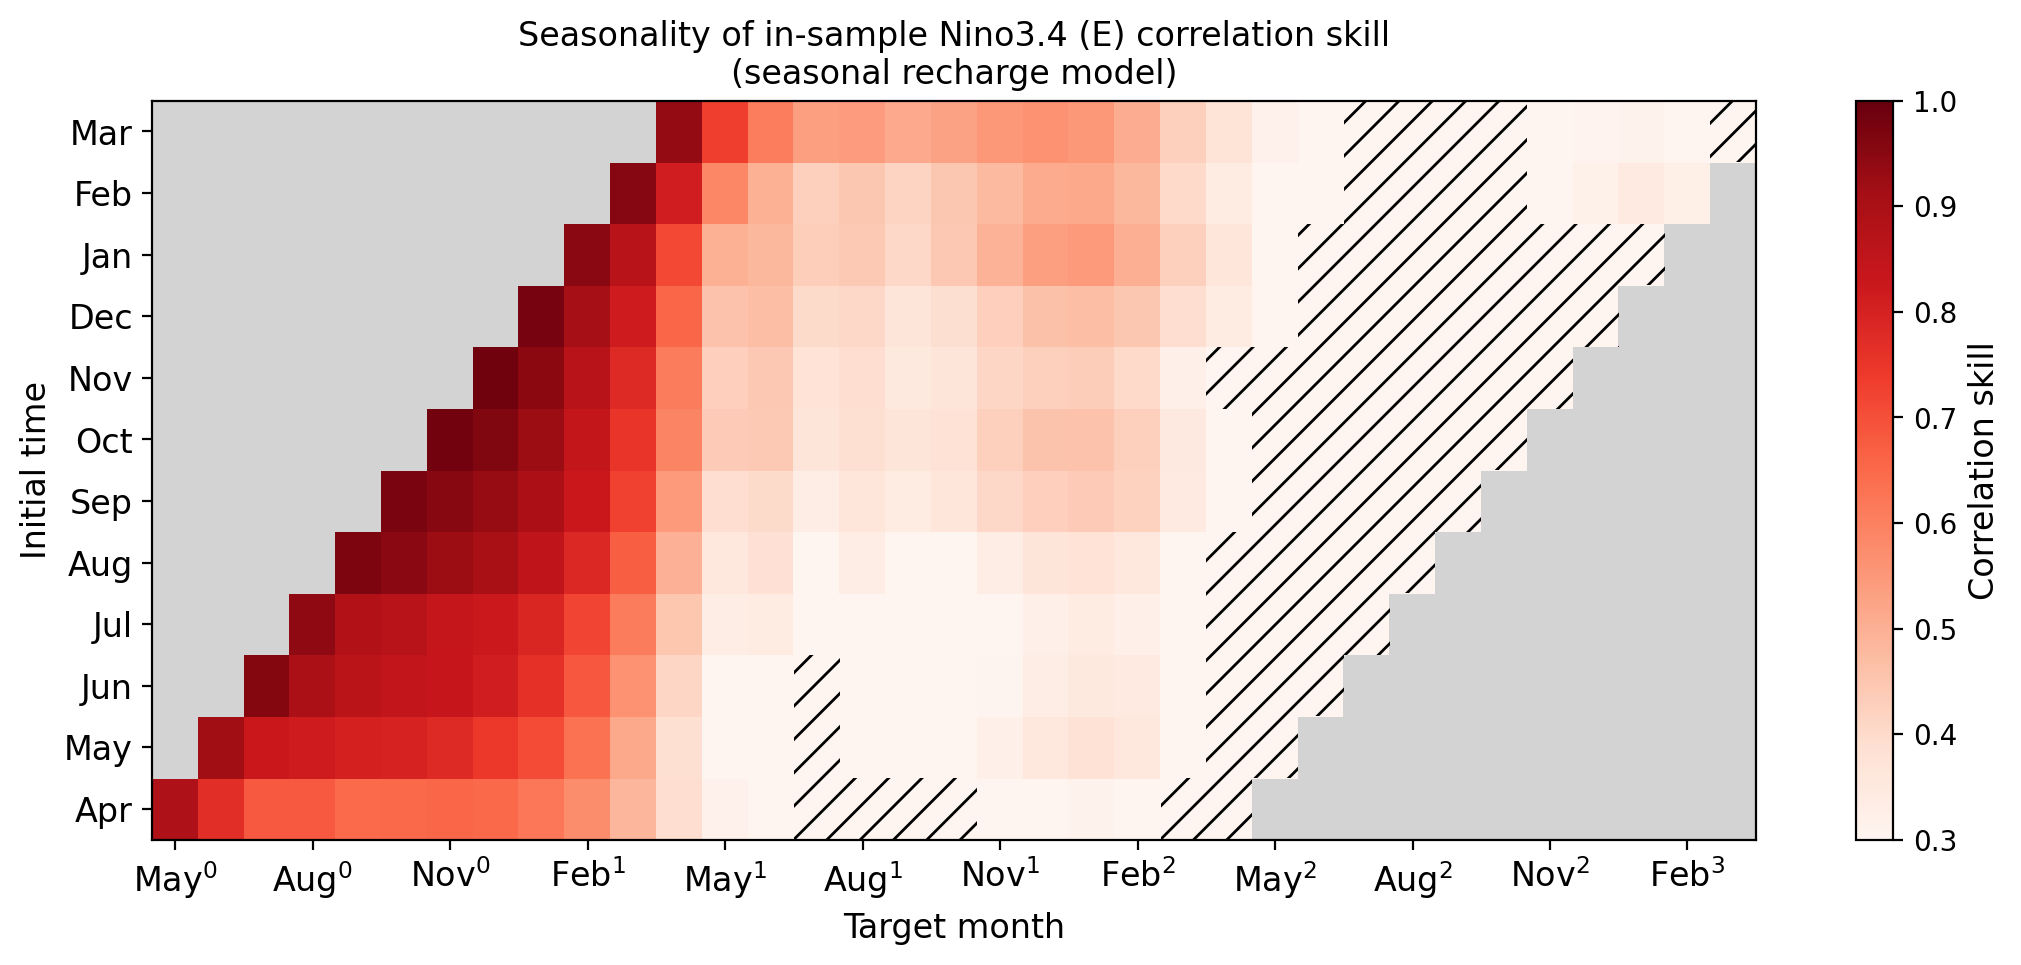

In [17]:
for var, label in (("I", "I"), ("E", "Nino3.4 (E)")):
    skill, signif = dg.seasonality_skill_matrix(hc, var)
    pl.plot_seasonality_skill(skill, signif,
        f"Seasonality of in-sample {label} correlation skill\n(seasonal recharge model)", max_lead=hc.max_lead)

## 8. Regression maps of the four latent parts

SST regressed on the standardised `E_I`, `E_D`, `I_I`, `I_D` (per 1 sigma). Needs the gridded SST,
so it works with `DATA_SOURCE = "oras"` (and `cartopy`); otherwise the cell is skipped. Row 0 of the
filter output is its initialisation and is dropped.

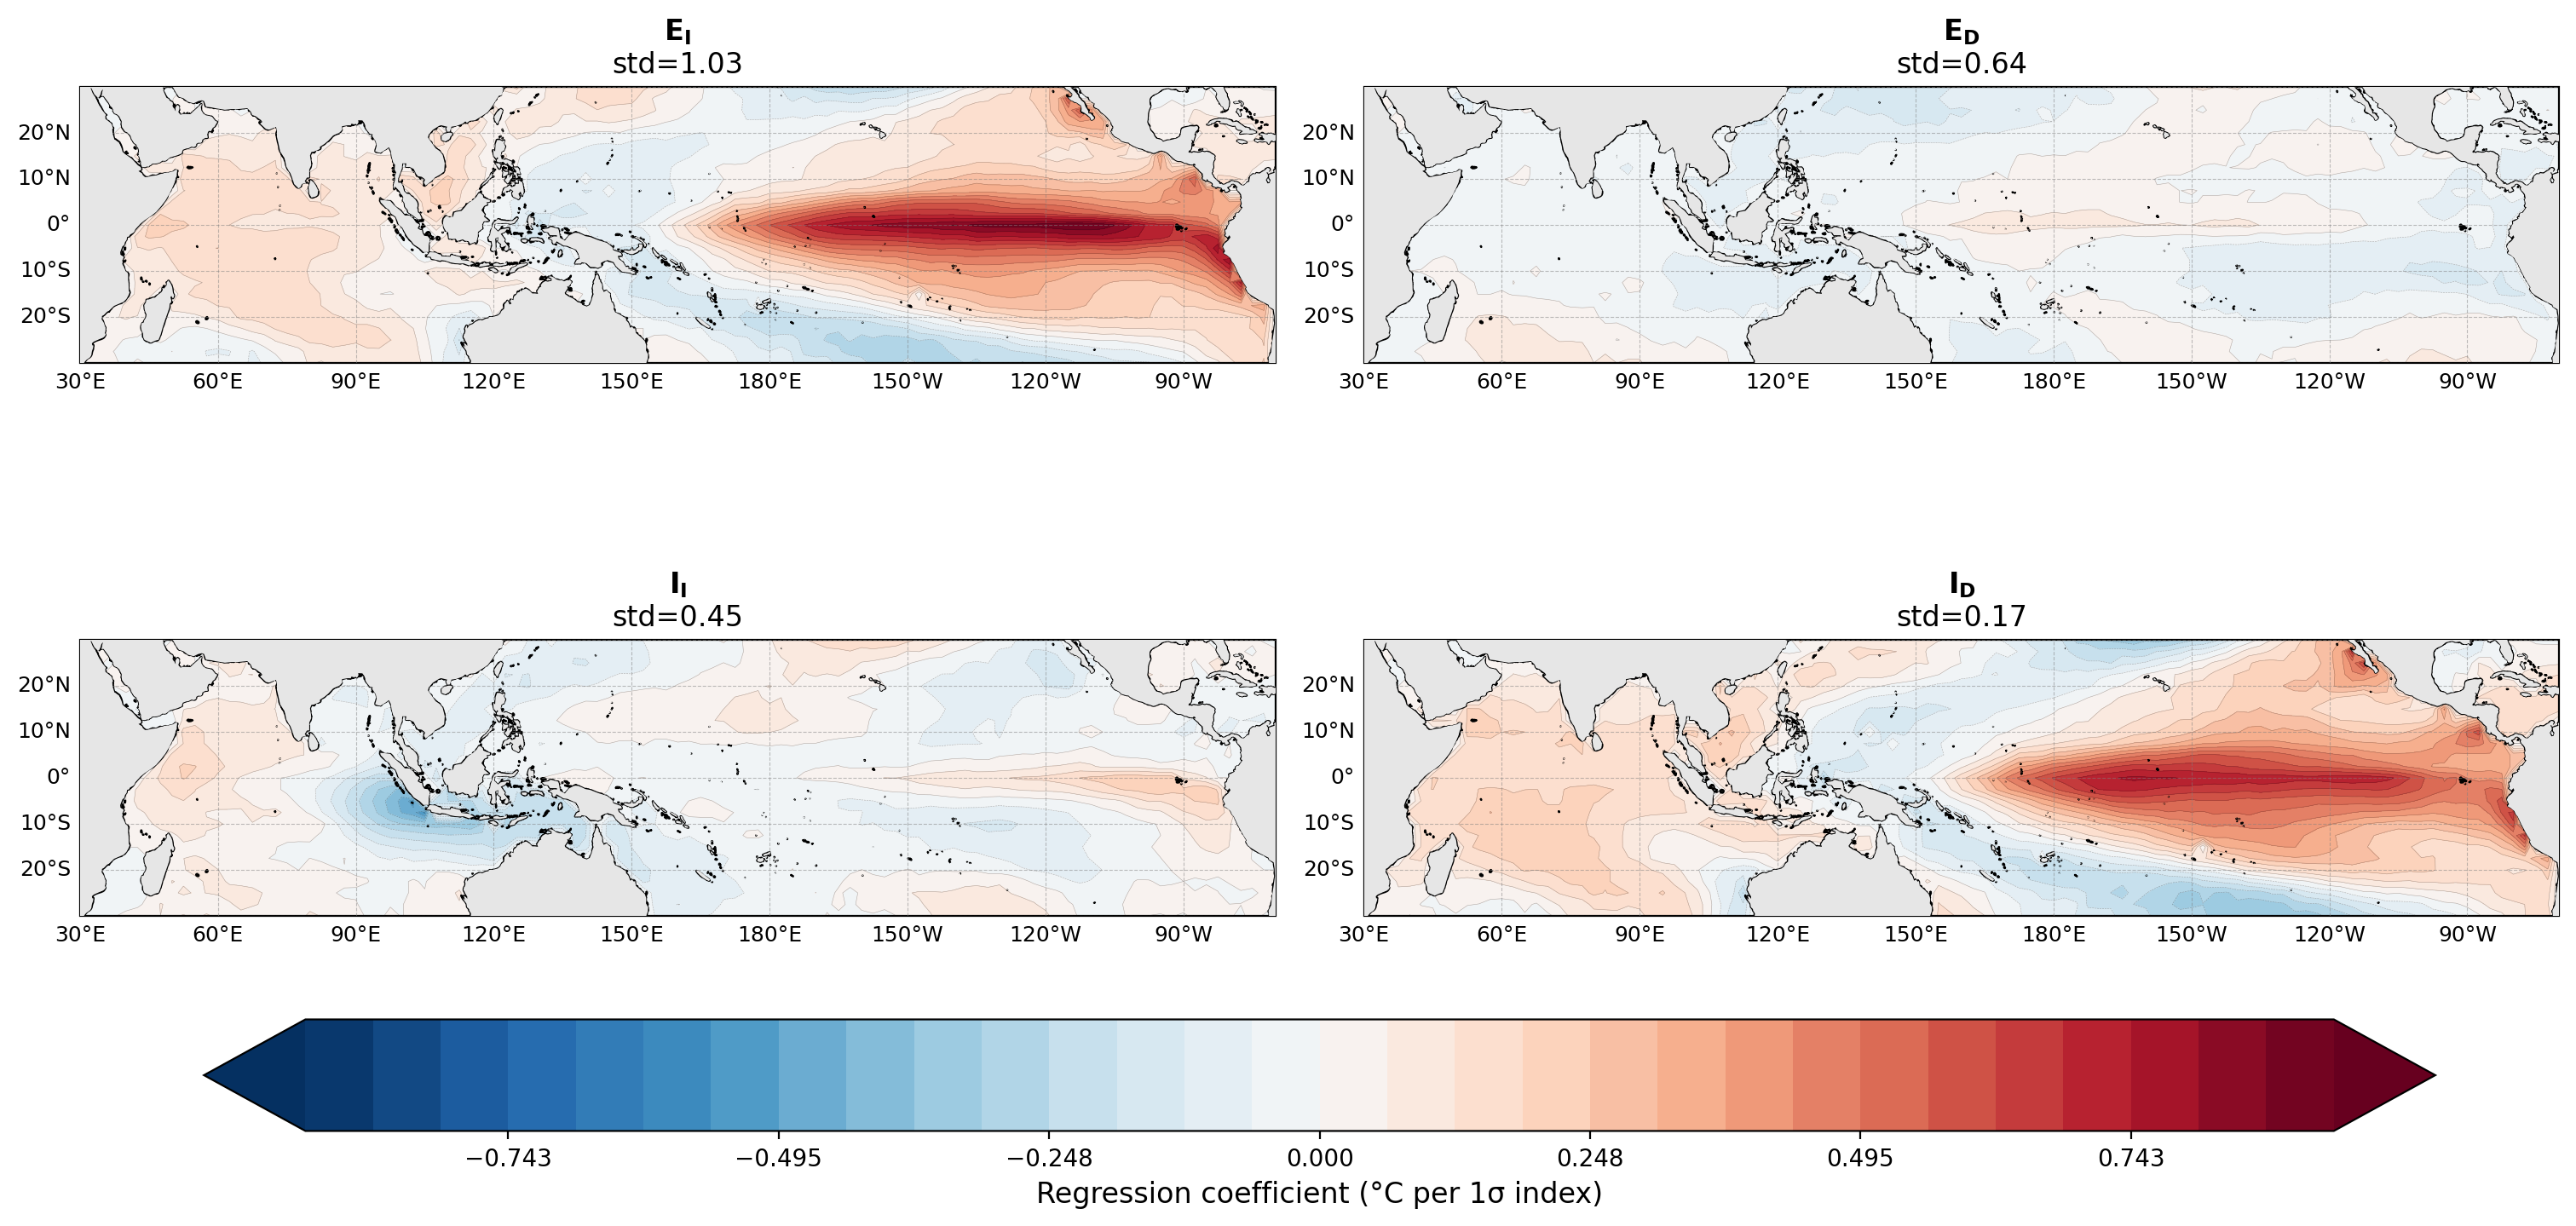

In [18]:
if sst_d is None:
    print("Skipped: maps need the gridded SST (DATA_SOURCE = 'oras').")
else:
    from explicit_enso_iod_model import climate_base as cb
    x = model.x_kalman[1:]
    field = sst_d.transpose("time", "lat", "lon").isel(time=slice(1, None))
    reg_maps_std, sigmas = cb.regression_maps(
        field, {"E_I": x[:, 0], "E_D": x[:, 1], "I_I": x[:, 2], "I_D": x[:, 3]})
    fig, axes = pl.plot_regression_maps(reg_maps_std, sigmas)